# Lending Club Loan Approval System

**Data snapshot (default repo sample):** `data/loans.csv` (~6.3k rows, 2014-era Lending Club sample mirror).

If running with a different file, set `LENDING_CLUB_DATA_PATH` before execution.

## Business Background

Lending Club is a peer-to-peer lending company where individuals can borrow loans, and investors can fund those loans. Lending Club was founded in 2006 by Renaud Laplanche as a peer-to-peer (P2P) lending platform in San Francisco. It was one of the pioneers in the online lending space, where individual borrowers could obtain loans, and individual or institutional investors could invest in these loans to earn interest. The platform allowed for a more direct connection between lenders and borrowers, bypassing traditional banking intermediaries.

Read more here https://en.wikipedia.org/wiki/LendingClub

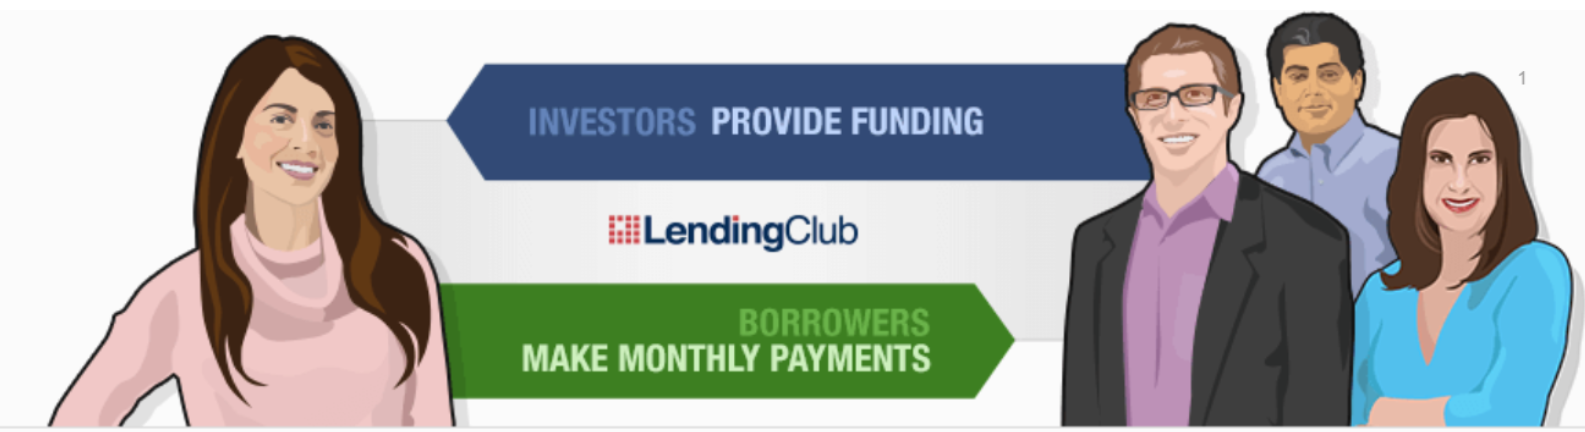

## Problem Statement

Now, whenever *Lending Club* approves a loan, there are two ways in which it is at risk:
- If LC approves a loan and the borrower fails to repay it on time
- If LC rejects a loan despite the borrower being capable of repaying the loan

Defaulting on loans can lead to significant financial losses for both the platform and investors. Similarly, not providing loans to credit-worthy customers can lead to missing out on potential revenue and profits. Therefore, a robust loan approval system is the need of the hour.

In the current loan approval process, underwriters evaluate loan applications by manually reviewing credit scores, income, debt, etc. and then, based on several parameters, either approve or reject a loan. This process is time-consuming and prone to errors.

Hence, Lending Club wants to build a loan approval system using Machine Learning models to automatically assess whether a given loan is likely to be repaid or whether the borrower is likely to default.

This is where you come in! As a budding data scientist, your goal is to help out Lending Club in creating this ML model that helps them predict whether a loan is likely to default or not.

## Data Understanding

You have been provided with around 38k loan application data from the Lending Club's website. The different columns and their description are mentioned below:

| Column Name         | Description                                                                                                                                                    |
|---------------------|----------------------------------------------------------------------------------------------------------------------------------------------------------------|
| id                  | A unique LC assigned ID for the loan listing. *(Integer)*                                                                                                       |
| member_id           | A unique LC assigned ID for the borrower member. *(Integer)*                                                                                                    |
| loan_amnt           | The listed amount of the loan applied for by the borrower. If at some point the credit department reduces the loan amount, it will be reflected in this value. *(Float)* |
| term                | The number of payments on the loan. Values are in months and can be either 36 or 60. *(Integer)*                                                                 |
| int_rate            | Interest rate on the loan. *(Float)*                                                                                                                            |
| installment         | The monthly payment owed by the borrower if the loan originates. *(Float)*                                                                                       |
| grade               | LC assigned loan grade. *(Categorical/String)*                                                                                                                  |
| sub_grade           | LC assigned loan subgrade. *(Categorical/String)*                                                                                                               |
| emp_length          | Employment length in years. Possible values are between 0 and 10, where 0 means less than one year and 10 means ten or more years. *(Integer)*                   |
| home_ownership      | The home ownership status provided by the borrower during registration. Values are: RENT, OWN, MORTGAGE, OTHER. *(Categorical/String)*                           |
| annual_inc          | The self-reported annual income provided by the borrower during registration. *(Float)*                                                                         |
| verification_status | Indicates if income was verified by LC, not verified, or if the income source was verified. *(Categorical/String)*                                               |
| purpose             | A category provided by the borrower for the loan request. *(Categorical/String)*                                                                                |
| dti                 | A ratio calculated using the borrower’s total monthly debt payments (excluding mortgage and the requested LC loan), divided by the borrower’s self-reported income. *(Float)* |
| delinq_2yrs         | The number of 30+ days past-due incidences of delinquency in the borrower's credit file for the past 2 years. *(Integer)*                                         |
| inq_last_6mths      | The number of inquiries in the past 6 months (excluding auto and mortgage inquiries). *(Integer)*                                                                |
| open_acc            | The number of open credit lines in the borrower's credit file. *(Integer)*                                                                                       |
| pub_rec             | Number of derogatory public records. *(Integer)*                                                                                                                |
| revol_bal           | Total credit revolving balance. *(Float)*                                                                                                                       |
| revol_util          | Revolving line utilization rate, or the amount of credit the borrower is using relative to all available revolving credit. *(Float)*                             |
| total_acc           | The total number of credit lines currently in the borrower's credit file. *(Integer)*                                                                            |
| last_pymnt_amnt     | Last total payment amount received. *(Float)*                                                                                                                   |
| loan_status         | Current status of the loan. *(Categorical/String)*                                                                 
                  |

...

## Starter Code

### Necessary Imports

In [1]:
import pandas as pd
import numpy as np
import re
import math

import matplotlib.pyplot as plt

import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

from sklearn.impute import SimpleImputer

from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder

from sklearn.preprocessing import FunctionTransformer
from sklearn.preprocessing import MinMaxScaler

from imblearn.over_sampling import SMOTE


In [2]:
pd.set_option('display.max_columns', None)
import warnings
# Suppress all warnings
warnings.filterwarnings('ignore')

### Data Loading

In [3]:
## Load the dataset
import os
from pathlib import Path

# Priority order:
# 1) LENDING_CLUB_DATA_PATH env var
# 2) repo-local default: data/loans.csv
candidate_paths = []
if os.getenv("LENDING_CLUB_DATA_PATH"):
    candidate_paths.append(Path(os.getenv("LENDING_CLUB_DATA_PATH")).expanduser())

candidate_paths.append(Path("data/loans.csv").expanduser())

DATA_PATH = next((p for p in candidate_paths if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Lending Club dataset not found. Set LENDING_CLUB_DATA_PATH or place loans.csv at data/loans.csv"
    )

print(f"Using dataset: {DATA_PATH}")
df = pd.read_csv(DATA_PATH, encoding='ISO-8859-1')

Using dataset: data\loans.csv


In [4]:
## Observe the first few rows
## Do you observe any issues?
df.head()

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,fico_range_low,fico_range_high,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,last_fico_range_high,last_fico_range_low,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,annual_inc_joint,dti_joint,verification_status_joint,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_act_il,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m,acc_open_past_24mths,avg_cur_bal,bc_open_to_buy,bc_util,chargeoff_within_12_mths,delinq_amnt,mo_sin_old_il_acct,mo_sin_old_rev_tl_op,mo_sin_rcnt_rev_tl_op,mo_sin_rcnt_tl,mort_acc,mths_since_recent_bc,mths_since_recent_bc_dlq,mths_since_recent_inq,mths_since_recent_revol_delinq,num_accts_ever_120_pd,num_actv_bc_tl,num_actv_rev_tl,num_bc_sats,num_bc_tl,num_il_tl,num_op_rev_tl,num_rev_accts,num_rev_tl_bal_gt_0,num_sats,num_tl_120dpd_2m,num_tl_30dpd,num_tl_90g_dpd_24m,num_tl_op_past_12m,pct_tl_nvr_dlq,percent_bc_gt_75,pub_rec_bankruptcies,tax_liens,tot_hi_cred_lim,total_bal_ex_mort,total_bc_limit,total_il_high_credit_limit,revol_bal_joint,sec_app_fico_range_low,sec_app_fico_range_high,sec_app_earliest_cr_line,sec_app_inq_last_6mths,sec_app_mort_acc,sec_app_open_acc,sec_app_revol_util,sec_app_open_act_il,sec_app_num_rev_accts,sec_app_chargeoff_within_12_mths,sec_app_collections_12_mths_ex_med,sec_app_mths_since_last_major_derog,hardship_flag,hardship_type,hardship_reason,hardship_status,deferral_term,hardship_amount,hardship_start_date,hardship_end_date,payment_plan_start_date,hardship_length,hardship_dpd,hardship_loan_status,orig_projected_additional_accrued_interest,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term,year
0,37631762,NaN,11000,11000,11000,36 months,12.99,370.59,C,C2,E-6/Technical Sergeant,10+ years,MORTGAGE,60000.0,Not Verified,Dec-2014,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,debt_consolidation,Debt consolidation,395xx,MS,34.10,2,Sep-2000,670,674,0,1.0,NaN,11,0,9704,51.9,24,f,0.0,0.0,13332.729289,13332.73,11000.0,2332.73,0.00,0.0,0.0,Feb-2018,2.35,NaN,Aug-2018,674,670,0,1.0,1,Individual,NaN,NaN,NaN,1,0,253854,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18700.0,NaN,NaN,NaN,3,25385,8471.0,51.0,1,0,171.0,126,18,12,2,18.0,1.0,22.0,1.0,1,1,2,2,5,15,4,7,2,11,0.0,0,1,1,87.5,50.0,0,0,320015.0,45933,17300.0,80336,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,2014
1,37800170,NaN,18000,18000,18000,36 months,11.44,593.06,B,B4,director,3 years,MORTGAGE,109000.0,Not Verified,Dec-2014,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,debt_consolidation,Debt consolidation,117xx,NY,22.07,1,Dec-1984,675,679,0,1.0,NaN,15,0,40579,59.9,51,f,0.0,0.0,21332.769650,21332.77,18000.0,3332.77,0.00,0.0,0.0,Jan-2018,592.83,NaN,Oct-2018,729,725,0,1.0,1,Individual,NaN,NaN,NaN,1,0,456332,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,67800.0,NaN,NaN,NaN,5,32595,11682.0,66.5,1,0,140.0,360,8,8,6,8.0,43.0,8.0,1.0,4,4,9,5,19,5,12,40,9,15,1.0,0,1,1,92.2,40.0,0,0,515992.0,60608,34900.0,28192,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,2014
2,33411541,NaN,120

In [5]:
## Check the dataframe structure - datatypes and number of non-null rows
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6305 entries, 0 to 6304
Columns: 152 entries, id to year
dtypes: float64(72), int64(45), object(35)
memory usage: 7.3+ MB


In [6]:
## Check the shape
df.shape

(6305, 152)

In [7]:
def check_missing_values(df):
    null_counts = df.isna().sum()

    # Calculate the percentage of null values for each column
    # This is done by dividing the null counts by the total number of rows in 'df' (len(df))
    # and multiplying by 100 to convert it to a percentage
    null_percentage = (null_counts / len(df)) * 100

    # Creating a new DataFrame to hold null counts and percentages
    null_summary = pd.DataFrame({
        'Null Count': null_counts,
        'Null Percentage': null_percentage
    })

    # Filtering to only show columns with null values
    null_summary = null_summary[null_summary['Null Count'] > 0]

    # Displaying the null summary DataFrame
    if null_summary.shape[0] > 0:
        print(null_summary)
    else:
        print('No nulls present in dataframe.')
    
check_missing_values(df)

                        Null Count  Null Percentage
member_id                     6305       100.000000
emp_title                      349         5.535289
emp_length                     317         5.027756
desc                          5907        93.687550
mths_since_last_delinq        2498        39.619350
...                            ...              ...
settlement_status             6174        97.922284
settlement_date               6174        97.922284
settlement_amount             6174        97.922284
settlement_percentage         6174        97.922284
settlement_term               6174        97.922284

[69 rows x 2 columns]


#### Observations

- there are several columns that we should take care to remove from the model as they would only have data AFTER the underwriting decision has occured
- we have a combination of both ordinal and non-ordinal cateogorical variables that we should encode appropriately
- grade and sub-grade contain redundant data that we can represent more concisely upon ordinal encoding
- sub-grade is essentially a pre-binned FICO score
- some numerical data is 'corrupted' with non-numerical descriptors (ie. % or 'month') that we should remove so we can cast them into the appropriate numerical type
- emp_length and revol_util have null values.  we'll have to consider how to treat these.  Neither appears large enough to warrant dropping the column completely so we may consider imputing the missing values, at risk of introducing some inaccuracies to the data.
- after properly encoding & removing we can consider re-basing values to span 0 or at least occupy a space similar in magnitude so no one non-dependent variable dominates the model simply due to its magnitude
- term has only two values and could be encoded as an ordinal but we'd lose the information represented by the magnitude of the distance between months

### Data Cleaning

- Perform missing value treatment
- Remove extra symbols, characters, etc. from appropriate columns

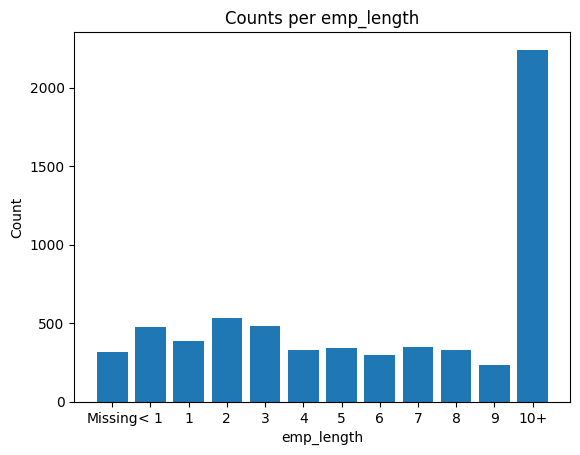

float64 [10.  3.  7.  5.  0.  8.  4.  9.  2.  1.  6.]
                        Null Count  Null Percentage
member_id                     6305       100.000000
emp_title                      349         5.535289
desc                          5907        93.687550
mths_since_last_delinq        2498        39.619350
mths_since_last_record        5272        83.616178
...                            ...              ...
settlement_status             6174        97.922284
settlement_date               6174        97.922284
settlement_amount             6174        97.922284
settlement_percentage         6174        97.922284
settlement_term               6174        97.922284

[68 rows x 2 columns]


In [8]:
## emp_length
if df['emp_length'].dtype != 'float64':
    # remove 'years'
    df['emp_length'] = df['emp_length'].str.replace(r'\s*year[s]?$', '', regex=True)
    df['emp_length'].unique().tolist()

    # handle nulls
    # visualize distribution
    el_ordered = ['Missing', '< 1', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10+']
    counts = df['emp_length'].fillna('Missing').value_counts(dropna=False).reindex(el_ordered)

    plt.bar(counts.index, counts.values)
    plt.xlabel('emp_length')
    plt.ylabel('Count')
    plt.title('Counts per emp_length')
    plt.show()

    # Impute
    # Fill Nulls w/ random sample values
    df['emp_length'] = df['emp_length'].apply(lambda x: np.random.choice(df['emp_length'].dropna()) if pd.isnull(x) else x)

    el_ordered = ['< 1', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10+']
    el_encoder = OrdinalEncoder(categories=[el_ordered])
    df['emp_length'] = el_encoder.fit_transform(df[['emp_length']])


print(df['emp_length'].dtype, df['emp_length'].unique())
check_missing_values(df)


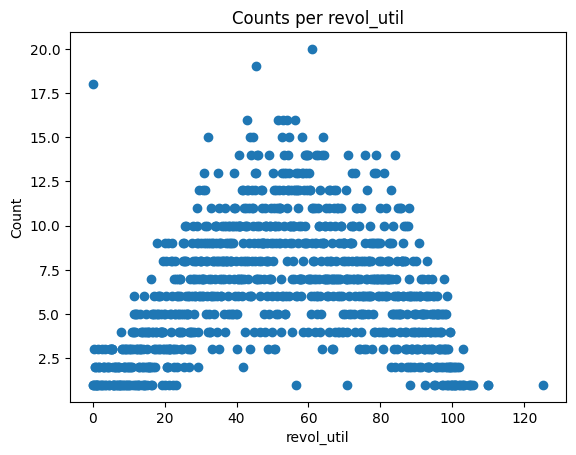

Mode:  0    61.0
Name: revol_util, dtype: float64
Mode count:  revol_util
61.0    20
Name: count, dtype: int64
                        Null Count  Null Percentage
member_id                     6305       100.000000
emp_title                      349         5.535289
desc                          5907        93.687550
mths_since_last_delinq        2498        39.619350
mths_since_last_record        5272        83.616178
...                            ...              ...
settlement_status             6174        97.922284
settlement_date               6174        97.922284
settlement_amount             6174        97.922284
settlement_percentage         6174        97.922284
settlement_term               6174        97.922284

[67 rows x 2 columns]


In [9]:
#revol_util
# visualize distribution
counts = df['revol_util'].value_counts()

plt.scatter(counts.index, counts.values)
plt.xlabel('revol_util')
plt.ylabel('Count')
plt.title('Counts per revol_util')
plt.show()

ru_mode = df['revol_util'].mode()
print('Mode: ',ru_mode )
print('Mode count: ', counts[ru_mode])
    
# Impute
# Fill nulls w/ mode
# Even though this is ordinal data, the mode overwhelms the data.  moreover, the mode, 0 is most likely equivalent for nulls
imputer = SimpleImputer(strategy='most_frequent')
df['revol_util'] = imputer.fit_transform(df[['revol_util']])

#convert to float
if df['revol_util'].dtype != 'float64':
    df['revol_util'] = df['revol_util'].str.replace('%', '', regex=True).astype(float)

check_missing_values(df)


In [10]:
#term
#convert to integer
try: # to make the code idempotent
    df['term'] = df['term'].str.replace(r'\s*month[s]?$', '', regex=True).astype(int)
except:
    pass

print(df['term'].unique().tolist())

[36, 60]


In [11]:
#int_rate
#convert to float
try: # to make the code idempotent
    df['int_rate'] = df['int_rate'].str.replace('%', '', regex=True).astype(float)
except:
    pass

print(df['int_rate'].unique().tolist())

[12.99, 11.44, 14.31, 8.67, 9.49, 15.99, 18.54, 16.49, 13.66, 11.99, 12.39, 14.99, 10.49, 19.99, 15.59, 6.99, 19.24, 8.19, 23.99, 17.14, 24.5, 21.99, 7.49, 22.99, 24.99, 17.86, 26.06, 6.49, 25.8, 20.99, 8.39, 15.61, 23.43, 10.15, 12.49, 13.35, 11.67, 14.49, 16.29, 17.57, 18.24, 7.12, 22.15, 18.99, 13.98, 16.99, 9.17, 10.99, 19.52, 20.2, 24.08, 7.69, 25.57, 25.99, 25.83, 25.89, 13.65, 16.59, 14.64, 15.31, 18.92, 7.9, 14.16, 20.49, 18.25, 19.47, 21.18, 22.45, 8.9, 9.67, 16.24, 14.98, 13.53, 12.85, 14.47, 23.4, 21.48, 22.9, 19.22, 20.5, 22.4, 19.97, 7.62, 6.03, 6.62, 23.7, 6.0]


In [12]:
##replace grade & sub-grape with numerical version of the finer of the two
try:
    df = df.drop(columns='grade') # redundant and less fidelity compared to sub_grade
except:
    pass
print(df.columns)

if df['sub_grade'].dtype == 'object': # to make the code idempotent
    grade_mapping = {
        'A1': 1,
        'A2': 2,
        'A3': 3,    
        'A4': 4,
        'A5': 5,
        
        'B1': 6,
        'B2': 7,
        'B3': 8,    
        'B4': 9,
        'B5': 10,
        
        'C1': 11,
        'C2': 12,
        'C3': 13,    
        'C4': 14,
        'C5': 15,

        'D1': 16,
        'D2': 17,
        'D3': 18,    
        'D4': 19,
        'D5': 20,

        'E1': 21,
        'E2': 22,
        'E3': 23,    
        'E4': 24,
        'E5': 25,

        'F1': 26,
        'F2': 27,
        'F3': 28,    
        'F4': 29,
        'F5': 30,

        'G1': 31,
        'G2': 32,
        'G3': 33,    
        'G4': 34,
        'G5': 35,

    }
    # Replace categorical values with numerical equivalents
    df['sub_grade'] = df['sub_grade'].map(grade_mapping)
print(sorted(df['sub_grade'].unique().tolist()))

Index(['id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv',
       'term', 'int_rate', 'installment', 'sub_grade', 'emp_title',
       ...
       'hardship_last_payment_amount', 'disbursement_method',
       'debt_settlement_flag', 'debt_settlement_flag_date',
       'settlement_status', 'settlement_date', 'settlement_amount',
       'settlement_percentage', 'settlement_term', 'year'],
      dtype='object', length=151)
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35]


In [13]:
##loan_status
# Keep only the two classes used in this binary underwriting exercise.
if df['loan_status'].dtype == 'object':  # idempotent when rerun
    allowed = ['Charged Off', 'Fully Paid']
    df = df[df['loan_status'].isin(allowed)].copy()
    ls_mapping = {'Charged Off': 0, 'Fully Paid': 1}
    df['loan_status'] = df['loan_status'].map(ls_mapping)

# Defensive cleanup in case the notebook is rerun on mixed-source data.
df = df.dropna(subset=['loan_status']).copy()
df['loan_status'] = df['loan_status'].astype(int)

print(df['loan_status'].unique().tolist())
df.head()

[1, 0]


,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,fico_range_low,fico_range_high,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,last_fico_range_high,last_fico_range_low,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,annual_inc_joint,dti_joint,verification_status_joint,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_act_il,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m,acc_open_past_24mths,avg_cur_bal,bc_open_to_buy,bc_util,chargeoff_within_12_mths,delinq_amnt,mo_sin_old_il_acct,mo_sin_old_rev_tl_op,mo_sin_rcnt_rev_tl_op,mo_sin_rcnt_tl,mort_acc,mths_since_recent_bc,mths_since_recent_bc_dlq,mths_since_recent_inq,mths_since_recent_revol_delinq,num_accts_ever_120_pd,num_actv_bc_tl,num_actv_rev_tl,num_bc_sats,num_bc_tl,num_il_tl,num_op_rev_tl,num_rev_accts,num_rev_tl_bal_gt_0,num_sats,num_tl_120dpd_2m,num_tl_30dpd,num_tl_90g_dpd_24m,num_tl_op_past_12m,pct_tl_nvr_dlq,percent_bc_gt_75,pub_rec_bankruptcies,tax_liens,tot_hi_cred_lim,total_bal_ex_mort,total_bc_limit,total_il_high_credit_limit,revol_bal_joint,sec_app_fico_range_low,sec_app_fico_range_high,sec_app_earliest_cr_line,sec_app_inq_last_6mths,sec_app_mort_acc,sec_app_open_acc,sec_app_revol_util,sec_app_open_act_il,sec_app_num_rev_accts,sec_app_chargeoff_within_12_mths,sec_app_collections_12_mths_ex_med,sec_app_mths_since_last_major_derog,hardship_flag,hardship_type,hardship_reason,hardship_status,deferral_term,hardship_amount,hardship_start_date,hardship_end_date,payment_plan_start_date,hardship_length,hardship_dpd,hardship_loan_status,orig_projected_additional_accrued_interest,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term,year
0,37631762,NaN,11000,11000,11000,36,12.99,370.59,12,E-6/Technical Sergeant,10.0,MORTGAGE,60000.0,Not Verified,Dec-2014,1,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,debt_consolidation,Debt consolidation,395xx,MS,34.10,2,Sep-2000,670,674,0,1.0,NaN,11,0,9704,51.9,24,f,0.0,0.0,13332.729289,13332.73,11000.0,2332.73,0.00,0.0,0.0,Feb-2018,2.35,NaN,Aug-2018,674,670,0,1.0,1,Individual,NaN,NaN,NaN,1,0,253854,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18700.0,NaN,NaN,NaN,3,25385,8471.0,51.0,1,0,171.0,126,18,12,2,18.0,1.0,22.0,1.0,1,1,2,2,5,15,4,7,2,11,0.0,0,1,1,87.5,50.0,0,0,320015.0,45933,17300.0,80336,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,2014
1,37800170,NaN,18000,18000,18000,36,11.44,593.06,9,director,3.0,MORTGAGE,109000.0,Not Verified,Dec-2014,1,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,debt_consolidation,Debt consolidation,117xx,NY,22.07,1,Dec-1984,675,679,0,1.0,NaN,15,0,40579,59.9,51,f,0.0,0.0,21332.769650,21332.77,18000.0,3332.77,0.00,0.0,0.0,Jan-2018,592.83,NaN,Oct-2018,729,725,0,1.0,1,Individual,NaN,NaN,NaN,1,0,456332,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,67800.0,NaN,NaN,NaN,5,32595,11682.0,66.5,1,0,140.0,360,8,8,6,8.0,43.0,8.0,1.0,4,4,9,5,19,5,12,40,9,15,1.0,0,1,1,92.2,40.0,0,0,515992.0,60608,34900.0,28192,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,2014
2,33411541,NaN,12000,12000,12000,60,14.31,281.16,14,Criminal Clerk,10.

##### Dropping the unnecessary columns

- Columns which are not required for analysis - `id`, `member_id`
- Columns which are not available at the time of loan approval (Check the data dictionary and problem statement to understand this more) - `installment` and `last_pymnt_amnt`

In [14]:
## Drop the above columns
#remove columns
try:
    #not related to independent variable
    df = df.drop(columns='id')
    df = df.drop(columns='member_id')

    #non-a priori
    df = df.drop(columns='installment')
    df = df.drop(columns='last_pymnt_amnt')
except:
    pass

df.columns

Index(['loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'term', 'int_rate',
       'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'annual_inc',
       ...
       'hardship_last_payment_amount', 'disbursement_method',
       'debt_settlement_flag', 'debt_settlement_flag_date',
       'settlement_status', 'settlement_date', 'settlement_amount',
       'settlement_percentage', 'settlement_term', 'year'],
      dtype='object', length=147)

In [15]:
## Check the dataframe again
df.head()

,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,fico_range_low,fico_range_high,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,next_pymnt_d,last_credit_pull_d,last_fico_range_high,last_fico_range_low,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,annual_inc_joint,dti_joint,verification_status_joint,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_act_il,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m,acc_open_past_24mths,avg_cur_bal,bc_open_to_buy,bc_util,chargeoff_within_12_mths,delinq_amnt,mo_sin_old_il_acct,mo_sin_old_rev_tl_op,mo_sin_rcnt_rev_tl_op,mo_sin_rcnt_tl,mort_acc,mths_since_recent_bc,mths_since_recent_bc_dlq,mths_since_recent_inq,mths_since_recent_revol_delinq,num_accts_ever_120_pd,num_actv_bc_tl,num_actv_rev_tl,num_bc_sats,num_bc_tl,num_il_tl,num_op_rev_tl,num_rev_accts,num_rev_tl_bal_gt_0,num_sats,num_tl_120dpd_2m,num_tl_30dpd,num_tl_90g_dpd_24m,num_tl_op_past_12m,pct_tl_nvr_dlq,percent_bc_gt_75,pub_rec_bankruptcies,tax_liens,tot_hi_cred_lim,total_bal_ex_mort,total_bc_limit,total_il_high_credit_limit,revol_bal_joint,sec_app_fico_range_low,sec_app_fico_range_high,sec_app_earliest_cr_line,sec_app_inq_last_6mths,sec_app_mort_acc,sec_app_open_acc,sec_app_revol_util,sec_app_open_act_il,sec_app_num_rev_accts,sec_app_chargeoff_within_12_mths,sec_app_collections_12_mths_ex_med,sec_app_mths_since_last_major_derog,hardship_flag,hardship_type,hardship_reason,hardship_status,deferral_term,hardship_amount,hardship_start_date,hardship_end_date,payment_plan_start_date,hardship_length,hardship_dpd,hardship_loan_status,orig_projected_additional_accrued_interest,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term,year
0,11000,11000,11000,36,12.99,12,E-6/Technical Sergeant,10.0,MORTGAGE,60000.0,Not Verified,Dec-2014,1,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,debt_consolidation,Debt consolidation,395xx,MS,34.10,2,Sep-2000,670,674,0,1.0,NaN,11,0,9704,51.9,24,f,0.0,0.0,13332.729289,13332.73,11000.0,2332.73,0.00,0.0,0.0,Feb-2018,NaN,Aug-2018,674,670,0,1.0,1,Individual,NaN,NaN,NaN,1,0,253854,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18700.0,NaN,NaN,NaN,3,25385,8471.0,51.0,1,0,171.0,126,18,12,2,18.0,1.0,22.0,1.0,1,1,2,2,5,15,4,7,2,11,0.0,0,1,1,87.5,50.0,0,0,320015.0,45933,17300.0,80336,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,2014
1,18000,18000,18000,36,11.44,9,director,3.0,MORTGAGE,109000.0,Not Verified,Dec-2014,1,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,debt_consolidation,Debt consolidation,117xx,NY,22.07,1,Dec-1984,675,679,0,1.0,NaN,15,0,40579,59.9,51,f,0.0,0.0,21332.769650,21332.77,18000.0,3332.77,0.00,0.0,0.0,Jan-2018,NaN,Oct-2018,729,725,0,1.0,1,Individual,NaN,NaN,NaN,1,0,456332,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,67800.0,NaN,NaN,NaN,5,32595,11682.0,66.5,1,0,140.0,360,8,8,6,8.0,43.0,8.0,1.0,4,4,9,5,19,5,12,40,9,15,1.0,0,1,1,92.2,40.0,0,0,515992.0,60608,34900.0,28192,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,2014
2,12000,12000,12000,60,14.31,14,Criminal Clerk,10.0,MORTGAGE,40000.0,Not Verified,Dec-2014,1,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,debt_consolida

### Exploratory Data Analysis

Let's understand the key drivers of loan default using EDA. This will form the preliminary analysis before we start with our machine learning model building part. We can understand the distributions of different variables, how they are related with loan default and so on.

#### Univariate Analysis

Perform univariate analysis on the following variables. Use visualizations and summary statistics wherever necessary. Document your overall observations as well
- `loan_status`
- `term`
- `grade`
- `purpose`
- `loan_amnt`
- `annual_inc`

*Note* - You can do additional analysis as well

<Figure size 640x480 with 0 Axes>

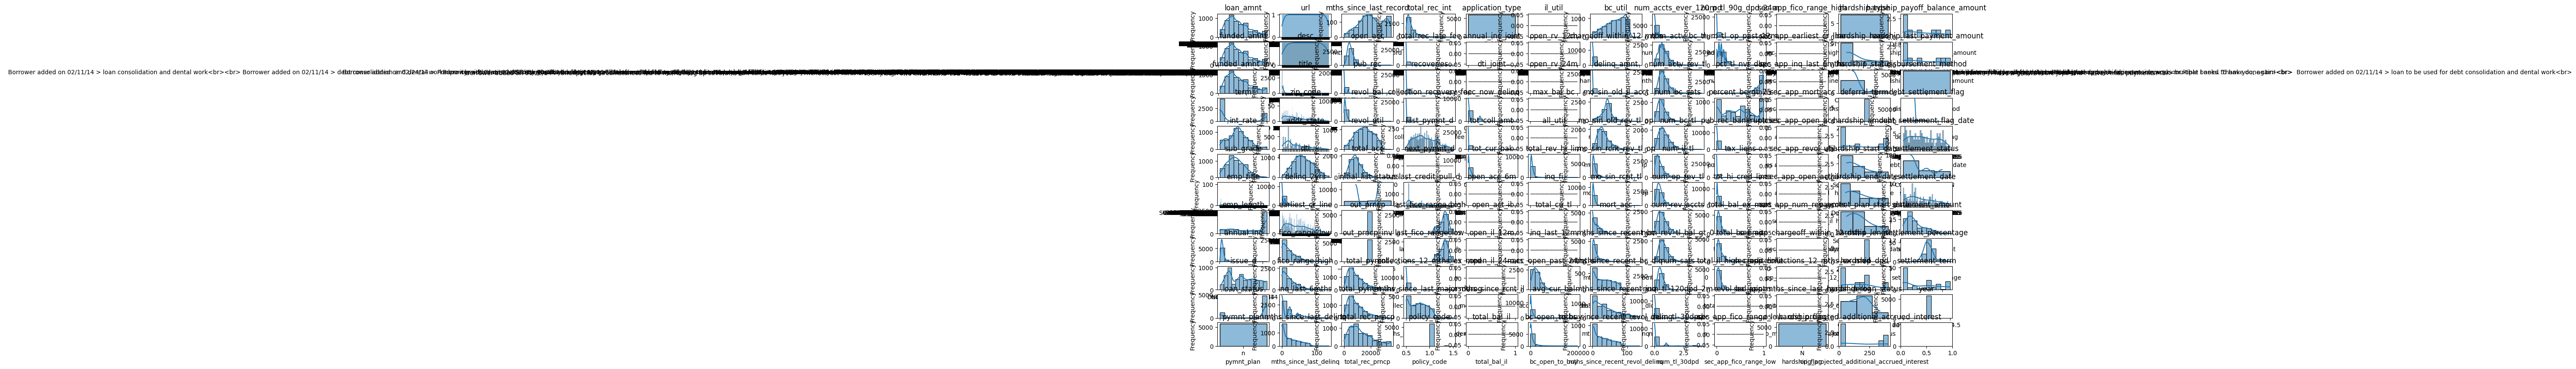

In [16]:
def getNonEncodedCols():
    ho_pattern = r'^home_ownership'
    non_encoded_columns = [s for s in df.columns if not re.match(ho_pattern, s)]
    p_pattern = r'^purpose'
    non_encoded_columns = [s for s in non_encoded_columns if not re.match(p_pattern, s)]
    vs_pattern = r'^verification_status'
    return [s for s in non_encoded_columns if not re.match(vs_pattern, s)]

# Loop through each non-encoded feature in the dataframe and print the value counts in form of histogram
def showCountPlots(myDf, myList):
    plt.clf()
    n = int(math.sqrt(len(myList))) + 1
    fig, axes = plt.subplots(n, n, figsize=(22, 10))

    for i, column in enumerate(myList):
        row_index = i // n  # Determine the row index (integer division)
        column_index = i % n  # Determine the column index (modulo)
        
        axe = axes[column_index][row_index]
        axe.set_title(column)
        axe.set_xlabel(column)  # Set x-axis label
        axe.set_ylabel('Frequency')  # Set y-axis label
        sns.histplot(myDf[column], kde=True, bins=10, ax=axe)  # `bins` specifies the number of bins

    plt.tight_layout()
    plt.show()

showCountPlots(df, getNonEncodedCols())


**Observations**

- `loan_status` - this is the dependent variable.  Charged Off is a loan that we should not underwrite.  Fully Paid is a loan we should underwrite.
- `term` - recorded in months, only 2 values: 36 & 60
- `grade & sub_grade` - Grade is a low-fi version of sub_grade so I've repurposed sub_grade as an ordinal encoding of the values
- `purpose` - String value rationale for the loan.  Now one hot encoded
- `loan_amnt` - In dollars
- `annual_inc` - Also in dollars.  Wide disparity looks like an outlier but is in fact matching our understanding of the nature of the "winner-take-all" economy representative of our modern era.

#### Bivariate Analysis

For the bivariate analysis, you can perform multiple analysis such as follows:

- How the default rate varies across the different variables
- Correlation Matrix
- etc.

Pre-Analysis Intuition
- annual_inc is self reported so if not verified may not be reliable.
- dti and annual_inc are redundant if the income portion is the same.  dti is most likely the more important of the two as it gives us a better idea of the proportion of free capital the borrower has to pay down the loan (1 - dti).  Since annual_inc is not entirely reliable, we may consider dropping it in favor of dti
- amount of revolving line of credit * revol_util = revol_bal.  revol_util gives us an idea of the outstanding debt the borrower is carrying, compared to how much they can carry.  This is similar to dti in that it offers a glimpse at the borrower's risk appetite.  Idea: non-revolving debt proportion = dti - revol_bal/annual_inc = total debt/income - revolving debt/statedincome.  This value should always be >= 0.  If stated income is overstated, the number may be significantly > 0.  If understated, < 0.  We may want to toy with a engineered feature here to help determine the reliability of the annual_inc amount.
- sub_grade is analogous/equivalent to a binned FICO score and should likely dominate whatever model we create.
- emp_length is analgous to a negative decay rate of income.  The reliability of static or increasing income over the life of the loan.
- Interest rate must be pre-calculated by LC.  It can't be selected by the user in an open-ended way or else they'd all select <= 0%.  Consequently, this gives us a proxy for the degree of risk that LC considers the borrower to have.  Should be similar and possibly overlap with the sub_grade score.  In fact, it's kind of cheating because ordinarily this wouldn't be available a priori.  Consequently, I intend to treat it as a second dependent variable to see if we can build not only a decisioning but also a pricing model.

<Figure size 640x480 with 0 Axes>

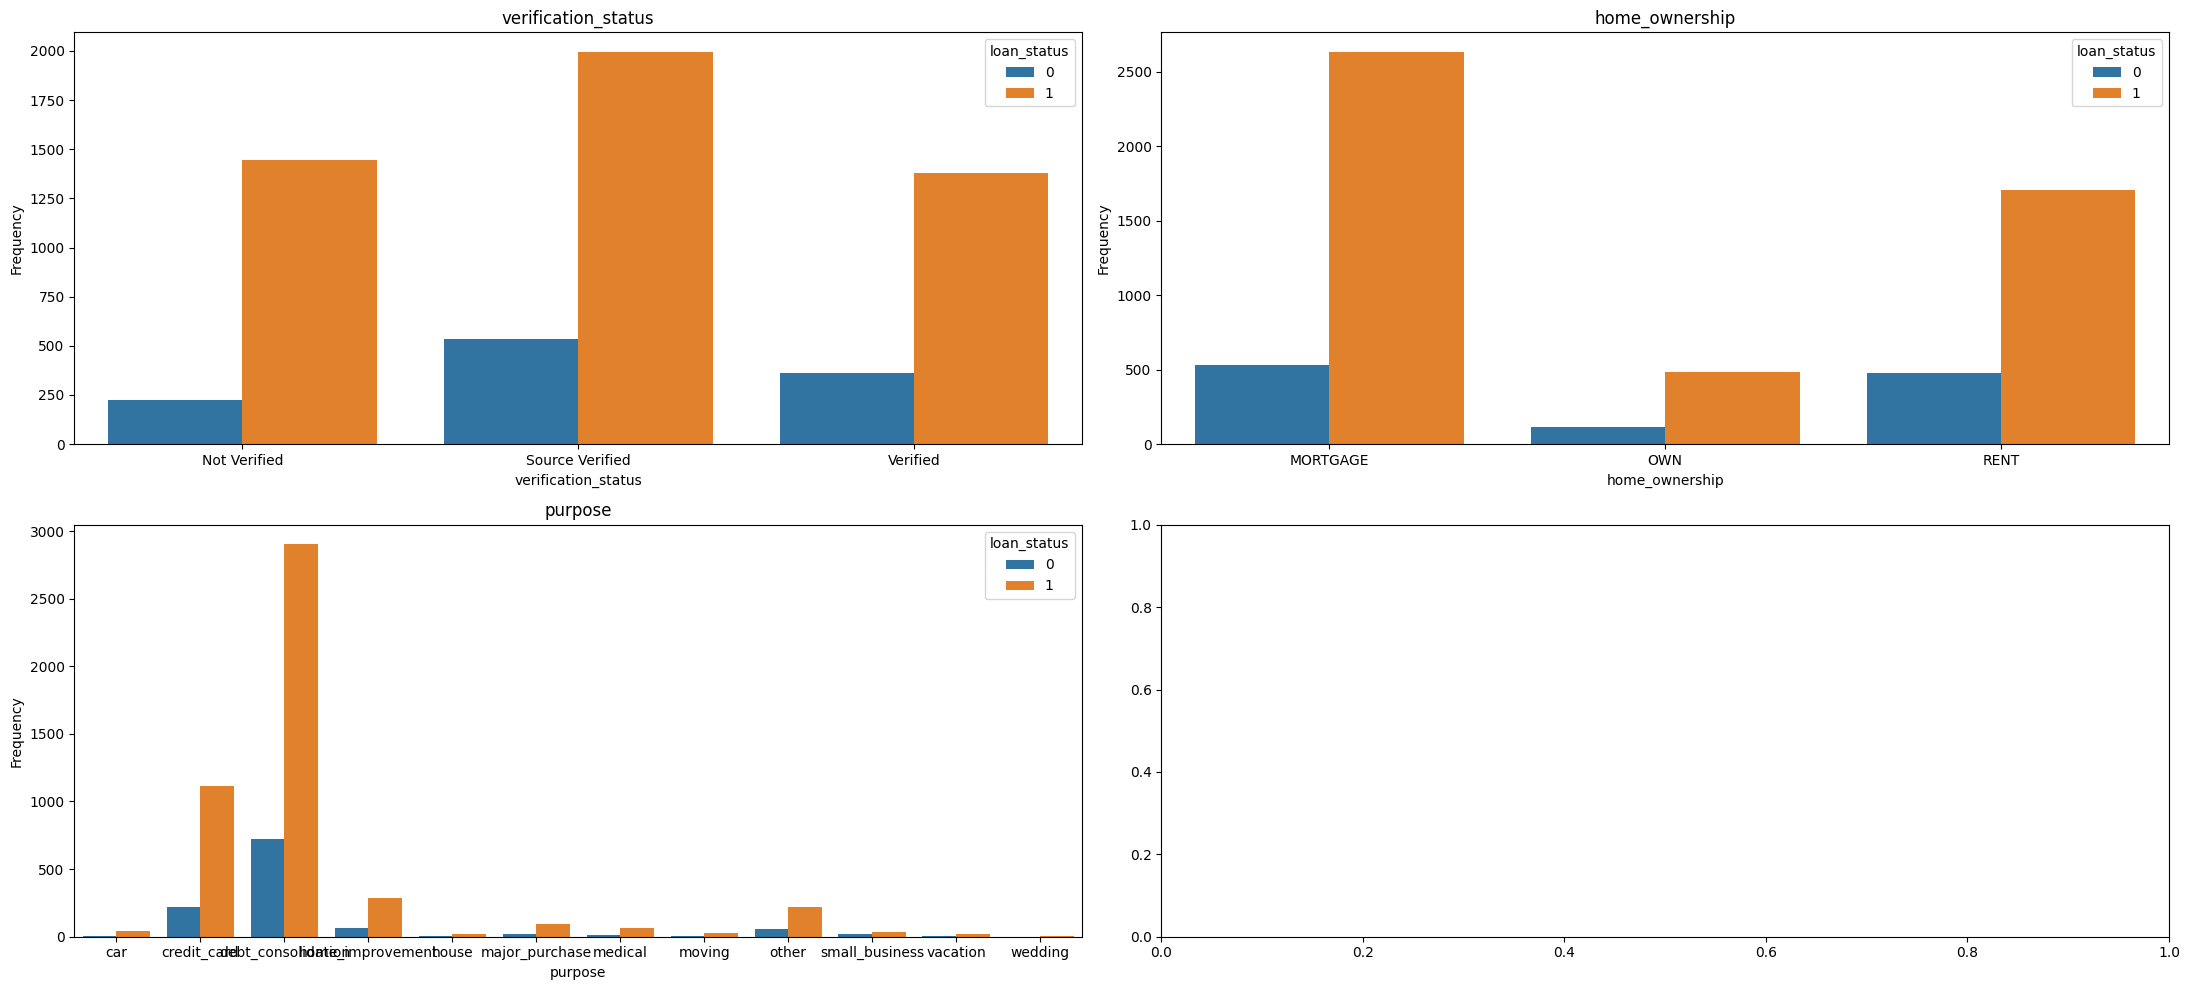

In [17]:
def getEncodedCols():
    return ['verification_status', 'purpose', 'home_ownership']

def showCorrPlots(myDf, myList):
    corrDF = myDf.copy()

    plt.clf()
    n = int(math.sqrt(len(myList))) + 1
    fig, axes = plt.subplots(n, n, figsize=(22, 10))

    for i, column in enumerate(myList):
        row_index = i // n  # Determine the row index (integer division)
        column_index = i % n  # Determine the column index (modulo)
        
        axe = axes[column_index][row_index]
        axe.set_title(column)
        axe.set_xlabel(column)  # Set x-axis label
        axe.set_ylabel('Frequency')  # Set y-axis label

        col_counts = corrDF.groupby([column, 'loan_status']).size().reset_index(name='counts')
        sns.barplot(ax=axe, x=column, y='counts', hue='loan_status', data=col_counts)

    plt.tight_layout()
    plt.show()

showCorrPlots(df, getEncodedCols())

## Observations
- For categorical variables, the proportion of charged off loans appears to consistently mimic the imbalance of the charged-off to not-charged-off values in the loan_status column.  There's little apparent correlation here.

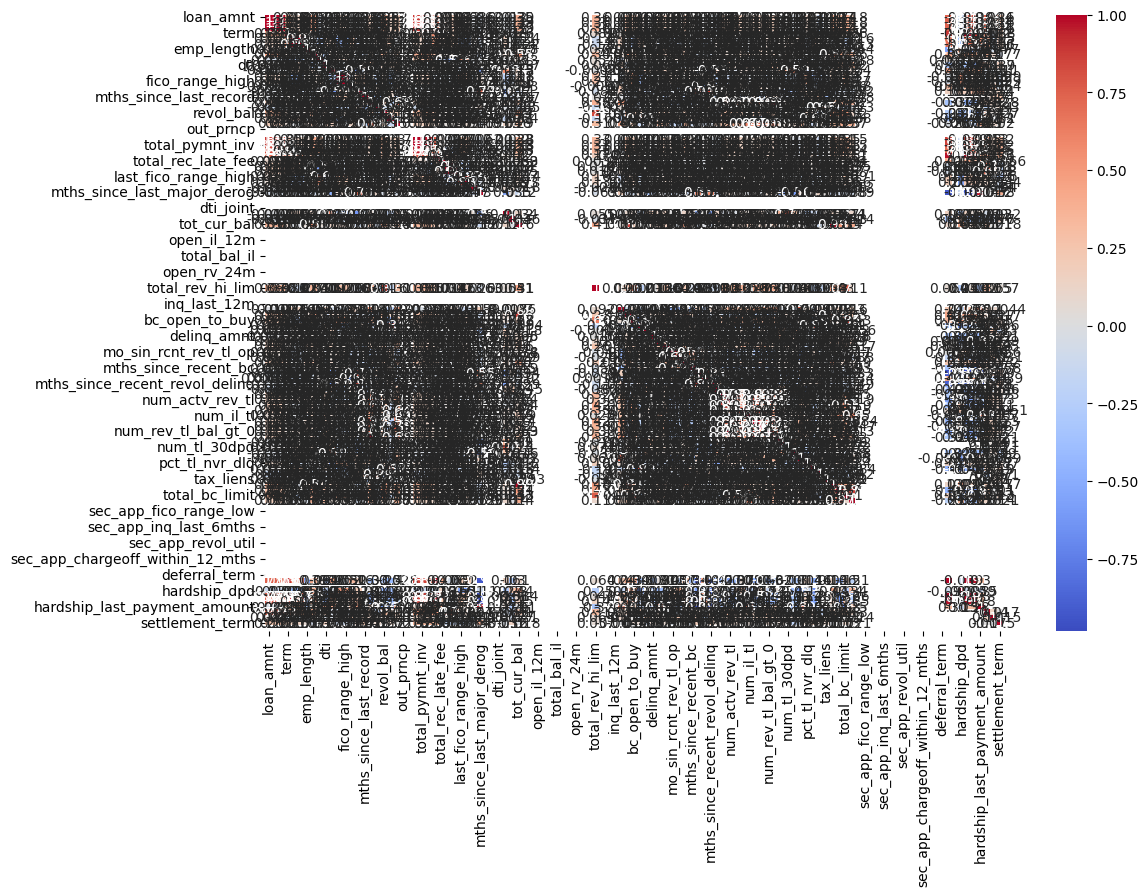

In [18]:
corr_matrix = df[getNonEncodedCols()].corr(numeric_only=True)
# Plot the heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.show()


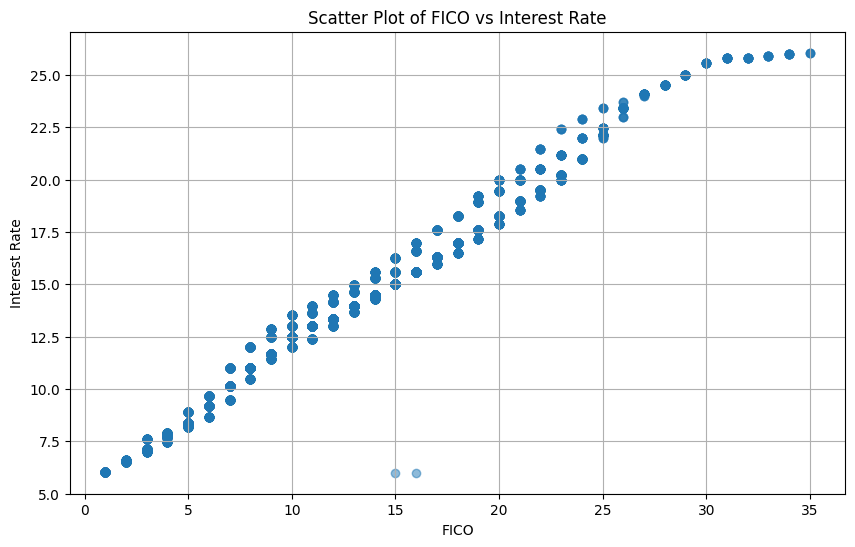

In [19]:
plt.figure(figsize=(10, 6))
plt.scatter(df['sub_grade'], df['int_rate'], alpha=0.5)
plt.title('Scatter Plot of FICO vs Interest Rate')
plt.xlabel('FICO')
plt.ylabel('Interest Rate')
plt.grid(True)
plt.show()

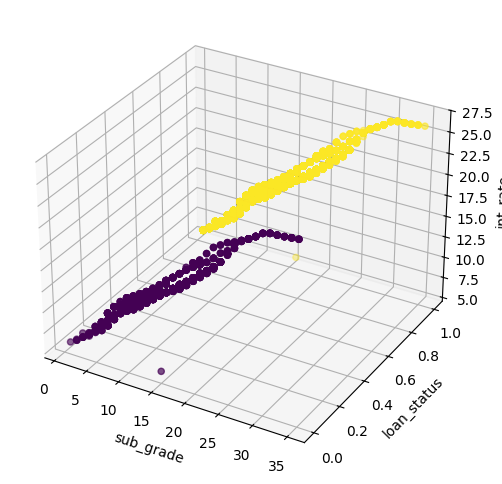

In [20]:
# 3D scatter plot
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

# Scatter plot
ax.scatter(df['sub_grade'], df['loan_status'], df['int_rate'], c=df['loan_status'], marker='o')

# Set labels
ax.set_xlabel('sub_grade')
ax.set_ylabel('loan_status')
ax.set_zlabel('int_rate')

# Show plot
plt.show()

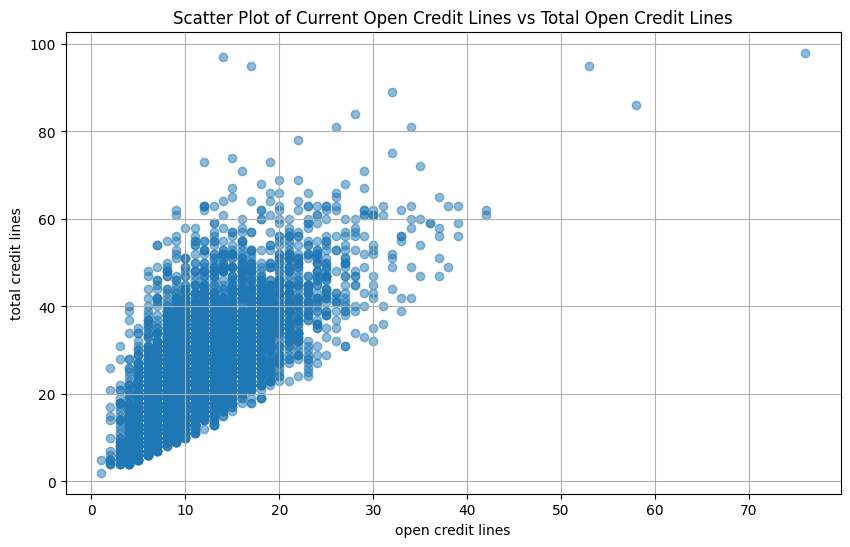

In [21]:
plt.figure(figsize=(10, 6))
plt.scatter(df['open_acc'], df['total_acc'], alpha=0.5)
plt.title('Scatter Plot of Current Open Credit Lines vs Total Open Credit Lines')
plt.xlabel('open credit lines')
plt.ylabel('total credit lines')
plt.grid(True)
plt.show()

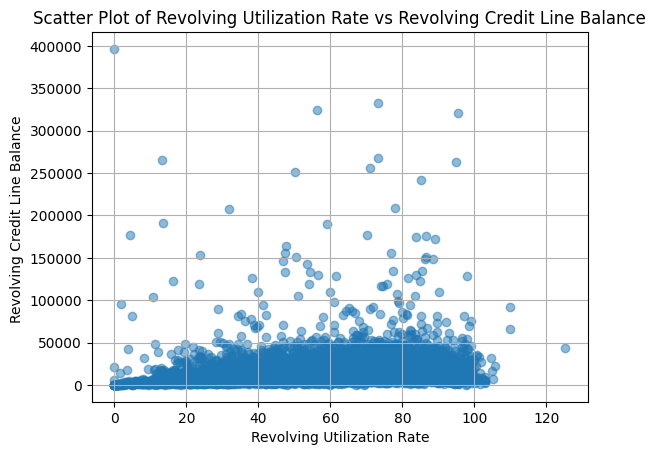

In [22]:
plt.scatter(df['revol_util'], df['revol_bal'], alpha=0.5)
plt.title('Scatter Plot of Revolving Utilization Rate vs Revolving Credit Line Balance')
plt.xlabel('Revolving Utilization Rate')
plt.ylabel('Revolving Credit Line Balance ')
plt.grid(True)
plt.show()

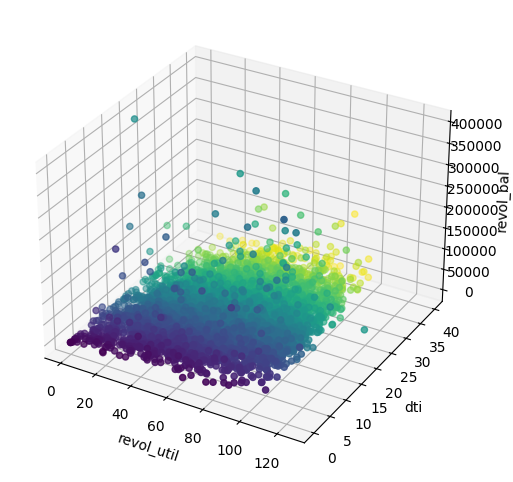

In [23]:
# 3D scatter plot
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

# Scatter plot
ax.scatter(df['revol_util'], df['dti'], df['revol_bal'], c=df['dti'], marker='o')

# Set labels
ax.set_xlabel('revol_util')
ax.set_ylabel('dti')
ax.set_zlabel('revol_bal')

# Show plot
plt.show()

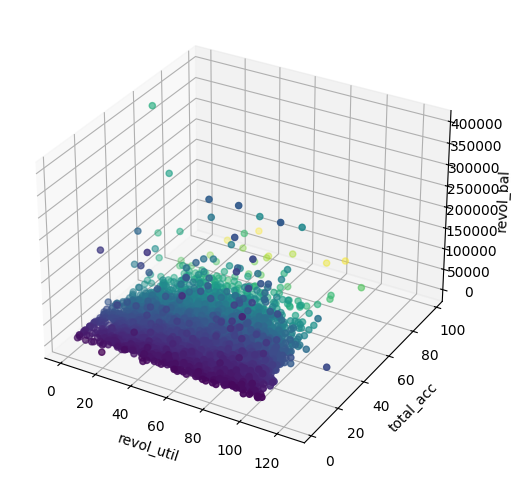

In [24]:
from mpl_toolkits.mplot3d import Axes3D

# 3D scatter plot
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

# Scatter plot
ax.scatter(df['revol_util'], df['total_acc'], df['revol_bal'], c=df['total_acc'], marker='o')

# Set labels
ax.set_xlabel('revol_util')
ax.set_ylabel('total_acc')
ax.set_zlabel('revol_bal')

# Show plot
plt.show()

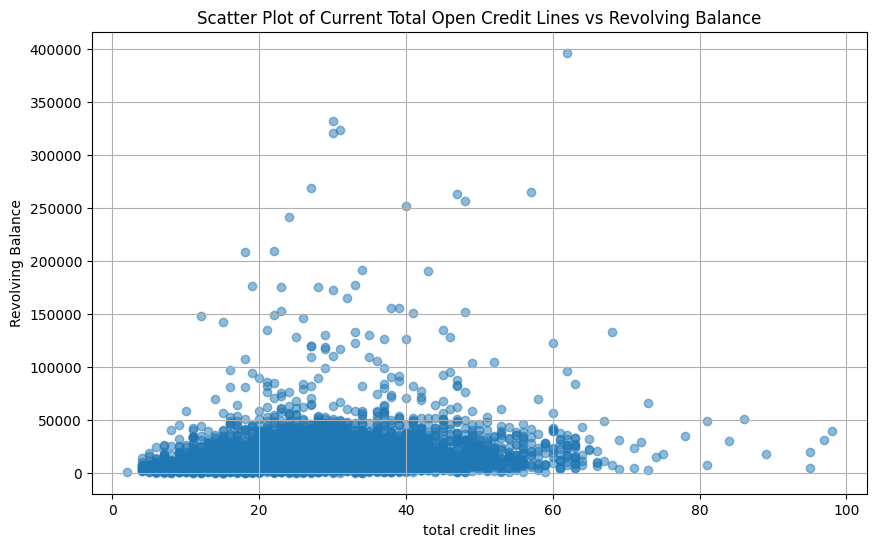

In [25]:
plt.figure(figsize=(10, 6))
plt.scatter(df['total_acc'], df['revol_bal'], alpha=0.5)
plt.title('Scatter Plot of Current Total Open Credit Lines vs Revolving Balance')
plt.xlabel('total credit lines')
plt.ylabel('Revolving Balance')
plt.grid(True)
plt.show()

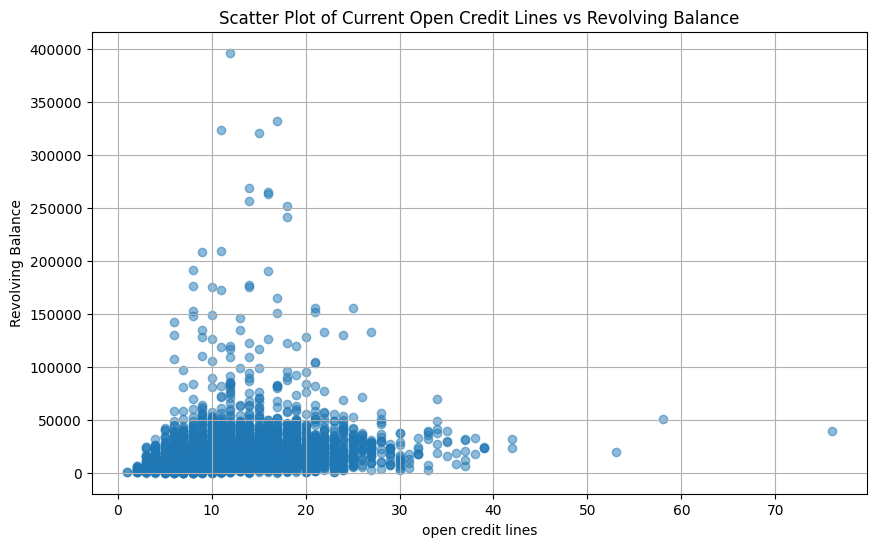

In [26]:
plt.figure(figsize=(10, 6))
plt.scatter(df['open_acc'], df['revol_bal'], alpha=0.5)
plt.title('Scatter Plot of Current Open Credit Lines vs Revolving Balance')
plt.xlabel('open credit lines')
plt.ylabel('Revolving Balance')
plt.grid(True)
plt.show()

## Takeaways
- As expected, interest rate and sub_grade are 96% correlated.  LC's interest rate pricing model is dominated by FICO score.  The missing 4% is important though.  sub_grade captures more information among the two as can be seen in the 3D chart comparing the nearly horizontal line that strays from the correlation present in the Fully Paid set of loans but not in the Charged Off loans.  Intuitively, this makes sense since it's relied upon to keep LC profitable in a competitive market.  Consequently, we should consider dropping sub_grade entirely, in favor of interest rate.
- There's a minimum linear support line for open lines of credit.  total lines = open lines + closed lines.  Above this line, is the body of closed lines.  We may want to tease apart total into open and closed and model these as separate features to remove the correlation between total and open.
- There appears to be a threshold between credit line balance and utilization rate wherein most borrowers reside.  Beyond that the data becomes sparse.  Analyzing across dti, it appears constant. This is counter-intuitive because one would expect utilization and/or balances to drop as a borrower's debt burden (dti) increases.
- It appears that credit line utilization and revolving balances drops off in-step as total and open lines of credit increase.  This pattern appears indicative of borrowers taking on more lines of credit than they need and is intuitive.

#### Pre-ML Data Pre-Processing

Before building the machine learning model, we shall perform
- encoding on all the categorical variables
- scaling
- handle class imbalance
- train-test split

##### Encoding variables

In [27]:
## non-ordinal categoricals
def replaceWithOneHot(df, colName):
    if colName not in df.columns:
        return
    print(df[colName].unique().tolist())
    encoder = OneHotEncoder(sparse_output=False)
    encoded = encoder.fit_transform(df[[colName]])

    # Convert the result to a DataFrame with appropriate column names
    encoded_df = pd.DataFrame(encoded, columns=encoder.categories_[0])
    encoded_df.columns = [colName + '_' + str(col) for col in encoded_df.columns]

    # Concatenate the one-hot encoded columns back to the original DataFrame
    df = pd.concat([df, encoded_df], axis=1)
    df.drop(colName, axis=1, inplace=True)
    return df

# home_ownership
df = replaceWithOneHot(df, 'home_ownership')
df = replaceWithOneHot(df, 'purpose')
df = replaceWithOneHot(df, 'verification_status')

df.head()

['MORTGAGE', 'RENT', 'OWN']
['debt_consolidation', 'other', 'major_purchase', 'credit_card', 'home_improvement', 'house', 'small_business', 'medical', 'moving', 'car', 'vacation', 'wedding', nan]
['Not Verified', 'Source Verified', 'Verified', nan]


,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,sub_grade,emp_title,emp_length,annual_inc,issue_d,loan_status,pymnt_plan,url,desc,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,fico_range_low,fico_range_high,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,next_pymnt_d,last_credit_pull_d,last_fico_range_high,last_fico_range_low,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,annual_inc_joint,dti_joint,verification_status_joint,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_act_il,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m,acc_open_past_24mths,avg_cur_bal,bc_open_to_buy,bc_util,chargeoff_within_12_mths,delinq_amnt,mo_sin_old_il_acct,mo_sin_old_rev_tl_op,mo_sin_rcnt_rev_tl_op,mo_sin_rcnt_tl,mort_acc,mths_since_recent_bc,mths_since_recent_bc_dlq,mths_since_recent_inq,mths_since_recent_revol_delinq,num_accts_ever_120_pd,num_actv_bc_tl,num_actv_rev_tl,num_bc_sats,num_bc_tl,num_il_tl,num_op_rev_tl,num_rev_accts,num_rev_tl_bal_gt_0,num_sats,num_tl_120dpd_2m,num_tl_30dpd,num_tl_90g_dpd_24m,num_tl_op_past_12m,pct_tl_nvr_dlq,percent_bc_gt_75,pub_rec_bankruptcies,tax_liens,tot_hi_cred_lim,total_bal_ex_mort,total_bc_limit,total_il_high_credit_limit,revol_bal_joint,sec_app_fico_range_low,sec_app_fico_range_high,sec_app_earliest_cr_line,sec_app_inq_last_6mths,sec_app_mort_acc,sec_app_open_acc,sec_app_revol_util,sec_app_open_act_il,sec_app_num_rev_accts,sec_app_chargeoff_within_12_mths,sec_app_collections_12_mths_ex_med,sec_app_mths_since_last_major_derog,hardship_flag,hardship_type,hardship_reason,hardship_status,deferral_term,hardship_amount,hardship_start_date,hardship_end_date,payment_plan_start_date,hardship_length,hardship_dpd,hardship_loan_status,orig_projected_additional_accrued_interest,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term,year,home_ownership_MORTGAGE,home_ownership_OWN,home_ownership_RENT,purpose_car,purpose_credit_card,purpose_debt_consolidation,purpose_home_improvement,purpose_house,purpose_major_purchase,purpose_medical,purpose_moving,purpose_other,purpose_small_business,purpose_vacation,purpose_wedding,purpose_nan,verification_status_Not Verified,verification_status_Source Verified,verification_status_Verified,verification_status_nan
0,11000.0,11000.0,11000.0,36.0,12.99,12.0,E-6/Technical Sergeant,10.0,60000.0,Dec-2014,1.0,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,Debt consolidation,395xx,MS,34.10,2.0,Sep-2000,670.0,674.0,0.0,1.0,NaN,11.0,0.0,9704.0,51.9,24.0,f,0.0,0.0,13332.729289,13332.73,11000.0,2332.73,0.00,0.0,0.0,Feb-2018,NaN,Aug-2018,674.0,670.0,0.0,1.0,1.0,Individual,NaN,NaN,NaN,1.0,0.0,253854.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18700.0,NaN,NaN,NaN,3.0,25385.0,8471.0,51.0,1.0,0.0,171.0,126.0,18.0,12.0,2.0,18.0,1.0,22.0,1.0,1.0,1.0,2.0,2.0,5.0,15.0,4.0,7.0,2.0,11.0,0.0,0.0,1.0,1.0,87.5,50.0,0.0,0.0,320015.0,45933.0,17300.0,80336.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,2014.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,18000.0,18000.0,18000.0,36.0,11.44,9.0,director,3.0,109000.0,Dec-2014,1.0,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,Debt consolidation,117xx,NY,22.07,1.0,Dec-1984,675.0,679.0,0.0,1.0,NaN,15.0,0.0,40579.0,59.9,51.0,f,0.0,0.0,21332.769650,21332.77,18000.0,3332.77,0.00,0.0,0.0,Jan-2018,NaN,Oct-2018,729.0,725.0,0.0,1.0,1.0,Individual,NaN,NaN,NaN,1.0,0.0,456332.

##### Feature Engineering

In [28]:

try:
    df['closed_acc'] = df['total_acc'] - df['open_acc']
    df.drop('total_acc', axis=1, inplace=True)
except:
    pass

check_missing_values(df)
df[df['closed_acc'].isnull()]

df.head()

                                     Null Count  Null Percentage
loan_amnt                                   363         5.757335
funded_amnt                                 363         5.757335
funded_amnt_inv                             363         5.757335
term                                        363         5.757335
int_rate                                    363         5.757335
...                                         ...              ...
verification_status_Not Verified              1         0.015860
verification_status_Source Verified           1         0.015860
verification_status_Verified                  1         0.015860
verification_status_nan                       1         0.015860
closed_acc                                  363         5.757335

[164 rows x 2 columns]


,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,sub_grade,emp_title,emp_length,annual_inc,issue_d,loan_status,pymnt_plan,url,desc,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,fico_range_low,fico_range_high,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,next_pymnt_d,last_credit_pull_d,last_fico_range_high,last_fico_range_low,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,annual_inc_joint,dti_joint,verification_status_joint,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_act_il,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m,acc_open_past_24mths,avg_cur_bal,bc_open_to_buy,bc_util,chargeoff_within_12_mths,delinq_amnt,mo_sin_old_il_acct,mo_sin_old_rev_tl_op,mo_sin_rcnt_rev_tl_op,mo_sin_rcnt_tl,mort_acc,mths_since_recent_bc,mths_since_recent_bc_dlq,mths_since_recent_inq,mths_since_recent_revol_delinq,num_accts_ever_120_pd,num_actv_bc_tl,num_actv_rev_tl,num_bc_sats,num_bc_tl,num_il_tl,num_op_rev_tl,num_rev_accts,num_rev_tl_bal_gt_0,num_sats,num_tl_120dpd_2m,num_tl_30dpd,num_tl_90g_dpd_24m,num_tl_op_past_12m,pct_tl_nvr_dlq,percent_bc_gt_75,pub_rec_bankruptcies,tax_liens,tot_hi_cred_lim,total_bal_ex_mort,total_bc_limit,total_il_high_credit_limit,revol_bal_joint,sec_app_fico_range_low,sec_app_fico_range_high,sec_app_earliest_cr_line,sec_app_inq_last_6mths,sec_app_mort_acc,sec_app_open_acc,sec_app_revol_util,sec_app_open_act_il,sec_app_num_rev_accts,sec_app_chargeoff_within_12_mths,sec_app_collections_12_mths_ex_med,sec_app_mths_since_last_major_derog,hardship_flag,hardship_type,hardship_reason,hardship_status,deferral_term,hardship_amount,hardship_start_date,hardship_end_date,payment_plan_start_date,hardship_length,hardship_dpd,hardship_loan_status,orig_projected_additional_accrued_interest,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term,year,home_ownership_MORTGAGE,home_ownership_OWN,home_ownership_RENT,purpose_car,purpose_credit_card,purpose_debt_consolidation,purpose_home_improvement,purpose_house,purpose_major_purchase,purpose_medical,purpose_moving,purpose_other,purpose_small_business,purpose_vacation,purpose_wedding,purpose_nan,verification_status_Not Verified,verification_status_Source Verified,verification_status_Verified,verification_status_nan,closed_acc
0,11000.0,11000.0,11000.0,36.0,12.99,12.0,E-6/Technical Sergeant,10.0,60000.0,Dec-2014,1.0,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,Debt consolidation,395xx,MS,34.10,2.0,Sep-2000,670.0,674.0,0.0,1.0,NaN,11.0,0.0,9704.0,51.9,f,0.0,0.0,13332.729289,13332.73,11000.0,2332.73,0.00,0.0,0.0,Feb-2018,NaN,Aug-2018,674.0,670.0,0.0,1.0,1.0,Individual,NaN,NaN,NaN,1.0,0.0,253854.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18700.0,NaN,NaN,NaN,3.0,25385.0,8471.0,51.0,1.0,0.0,171.0,126.0,18.0,12.0,2.0,18.0,1.0,22.0,1.0,1.0,1.0,2.0,2.0,5.0,15.0,4.0,7.0,2.0,11.0,0.0,0.0,1.0,1.0,87.5,50.0,0.0,0.0,320015.0,45933.0,17300.0,80336.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,2014.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,13.0
1,18000.0,18000.0,18000.0,36.0,11.44,9.0,director,3.0,109000.0,Dec-2014,1.0,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,Debt consolidation,117xx,NY,22.07,1.0,Dec-1984,675.0,679.0,0.0,1.0,NaN,15.0,0.0,40579.0,59.9,f,0.0,0.0,21332.769650,21332.77,18000.0,3332.77,0.00,0.0,0.0,Jan-2018,NaN,Oct-2018,729.0,725.0,0.0,1.0,1.0,Individual,NaN,NaN,NaN,1.0,0.0,456332.0,Na

##### Scaling

In [29]:
## Deep copy the dataframe to preserve progress so far
df_scaled = df.copy(deep=True)

annual_inc 3.963976609996606 nan
loan_amnt 3.0 nan
int_rate 0.7781512503836436 nan
sub_grade 0.0 nan
                                     Null Count  Null Percentage
loan_amnt                                   363         5.757335
funded_amnt                                 363         5.757335
funded_amnt_inv                             363         5.757335
term                                        363         5.757335
int_rate                                    363         5.757335
...                                         ...              ...
verification_status_Not Verified              1         0.015860
verification_status_Source Verified           1         0.015860
verification_status_Verified                  1         0.015860
verification_status_nan                       1         0.015860
closed_acc                                  363         5.757335

[164 rows x 2 columns]


<Figure size 640x480 with 0 Axes>

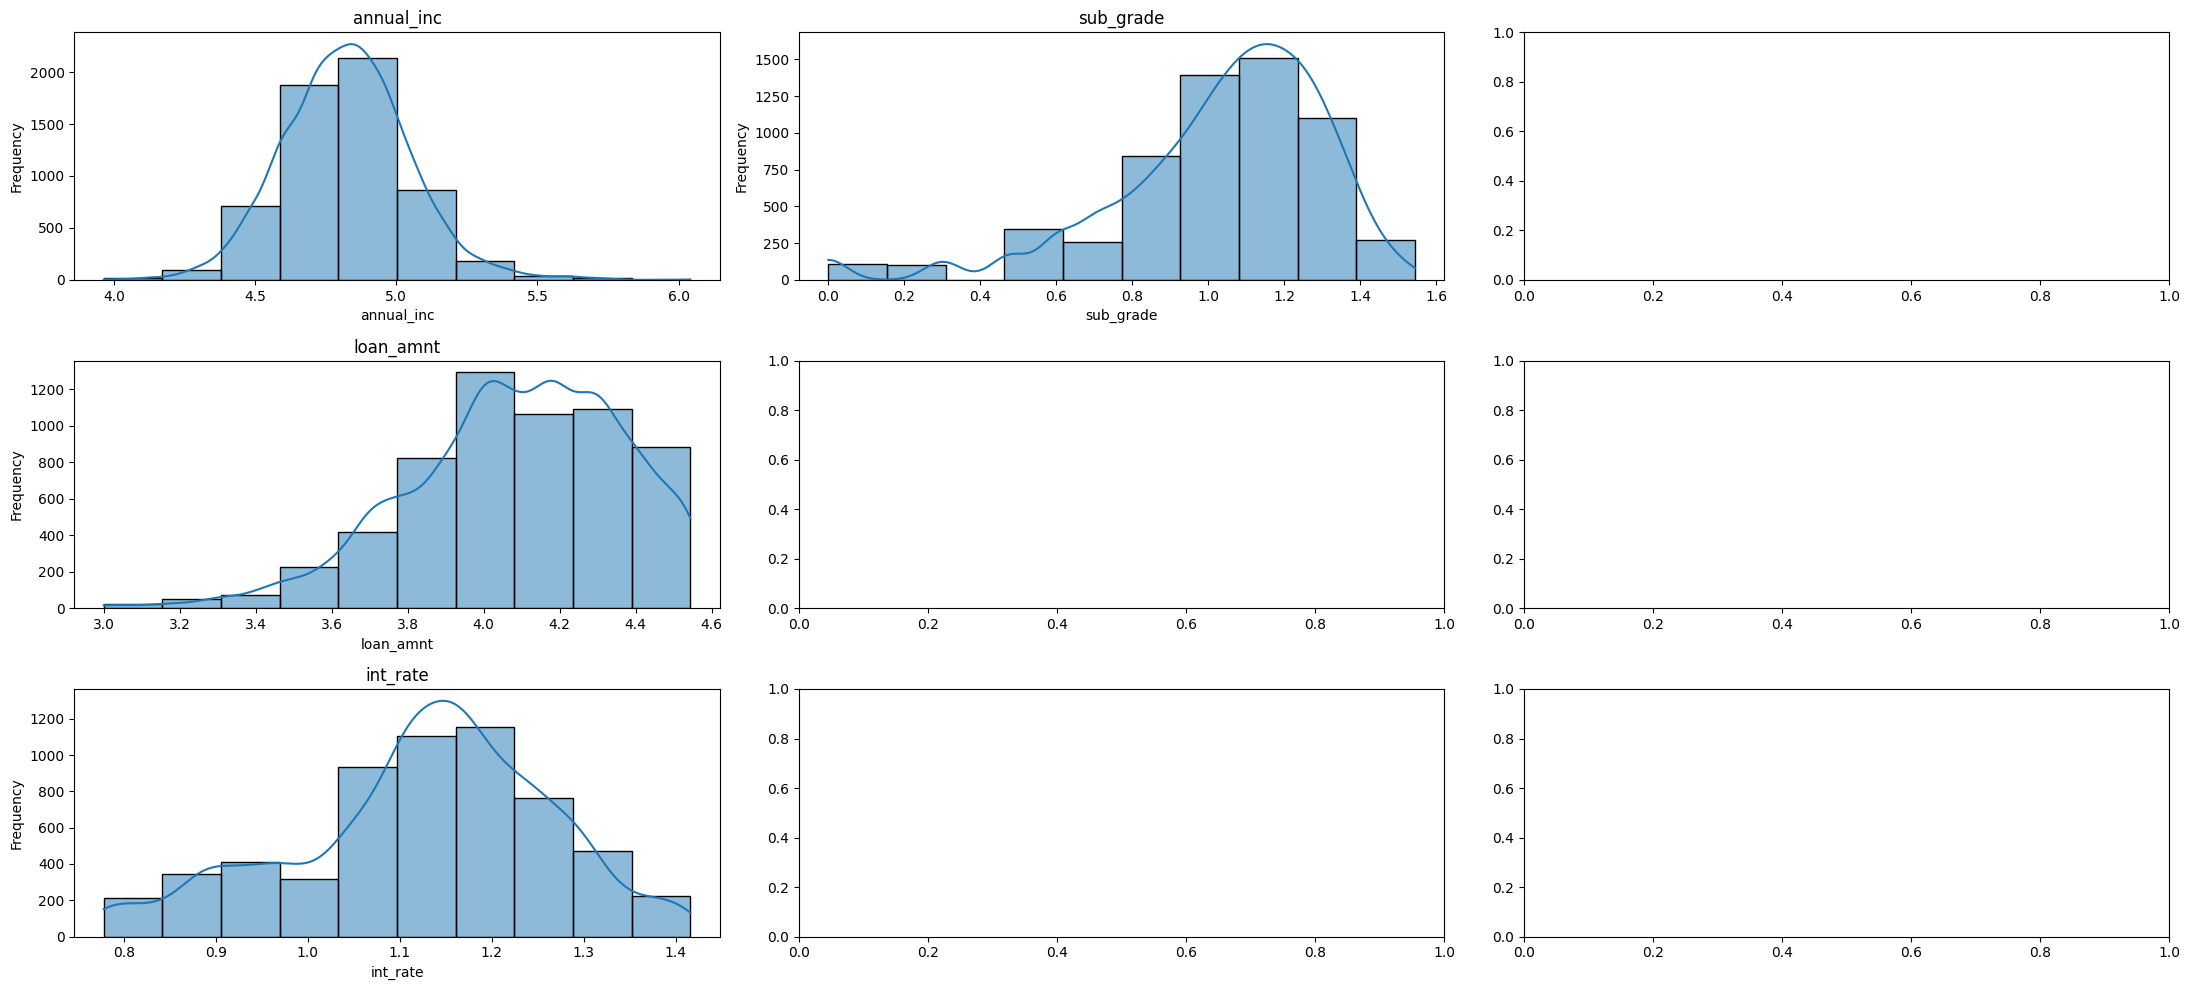

In [30]:
## left skewed features -- apply Log10 scaling
left_skewed_features = ['annual_inc', 'loan_amnt', 'int_rate', 'sub_grade']
log_transformer = FunctionTransformer(np.log10)

for col in left_skewed_features:
    #df_scaled[col] = df_scaled[col].apply(lambda x: np.log10(x) if x > 0 else 0)
    df_scaled[col] = log_transformer.transform(df[[col]])
    vals = sorted(df_scaled[col].unique().tolist())
    print(col, vals[0], vals[-1]) # check that there are no +/-inf

check_missing_values(df_scaled)
showCountPlots(df_scaled, left_skewed_features)

funded_amnt 0.0 1.0000000000000002
funded_amnt_inv 0.0 1.0000000000000002
term 0.0 1.0
emp_length 0.0 1.0
loan_status 0.0 1.0
dti 0.0 1.0
delinq_2yrs 0.0 1.0
fico_range_low 0.0 1.0
fico_range_high 0.0 1.0
inq_last_6mths 0.0 1.0
mths_since_last_delinq 0.0 1.0
mths_since_last_record 0.0 1.0
open_acc 0.0 1.0
pub_rec 0.0 1.0
revol_bal 0.0 1.0
revol_util 0.0 1.0
out_prncp 0.0 0.0
out_prncp_inv 0.0 0.0
total_pymnt 0.0 1.0
total_pymnt_inv 0.0 1.0000000000000002
total_rec_prncp 0.0 1.0
total_rec_int 0.0 1.0
total_rec_late_fee 0.0 1.0
recoveries 0.0 1.0
collection_recovery_fee 0.0 0.9999999999999999
last_fico_range_high 0.0 0.9999999999999999
last_fico_range_low 0.0 1.0
collections_12_mths_ex_med 0.0 1.0
mths_since_last_major_derog 0.0 1.0
policy_code 0.0 0.0
acc_now_delinq 0.0 1.0
tot_coll_amt 0.0 1.0
tot_cur_bal 0.0 1.0
total_rev_hi_lim 0.0 1.0
acc_open_past_24mths 0.0 1.0
avg_cur_bal 0.0 1.0
bc_open_to_buy 0.0 0.9999999999999999
bc_util 0.0 1.0
chargeoff_within_12_mths 0.0 1.0
delinq_amnt 0.

<Figure size 640x480 with 0 Axes>

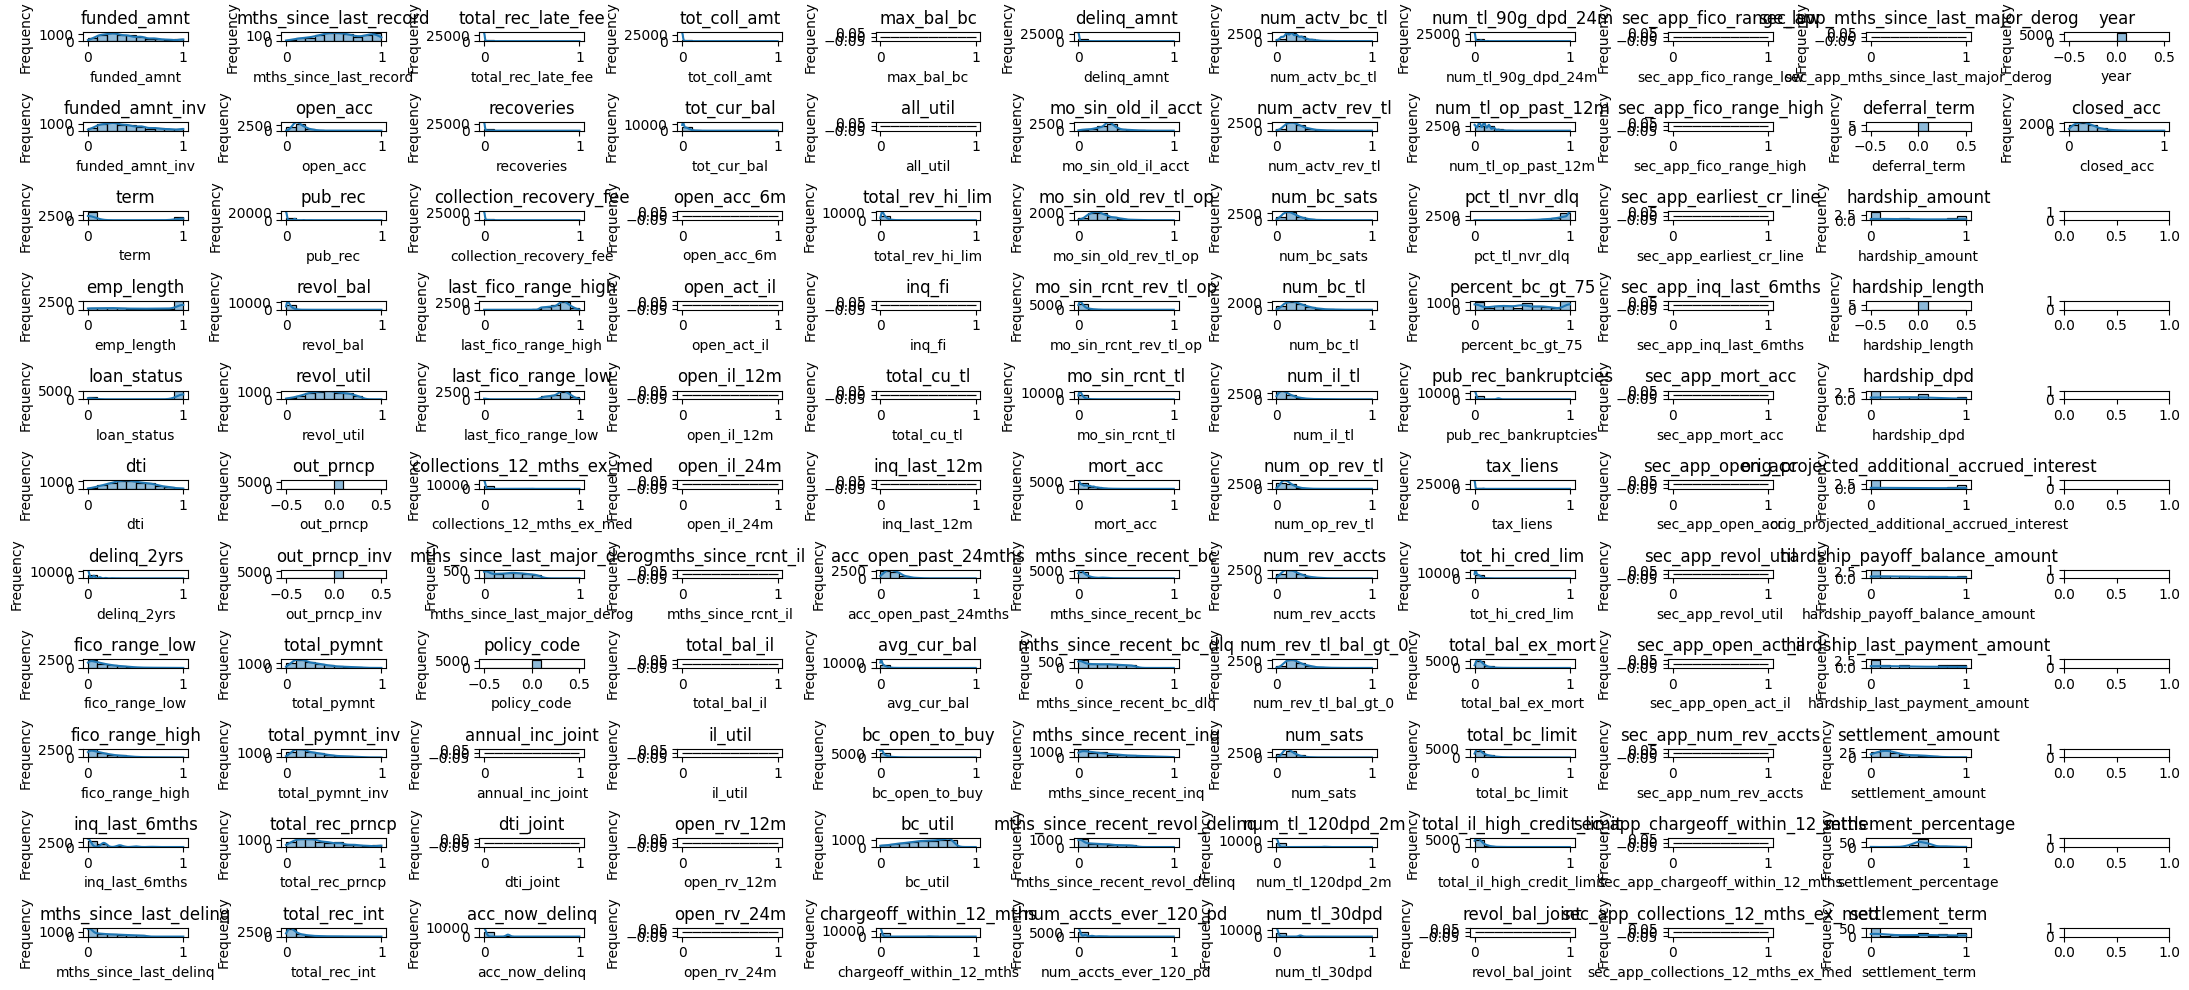

In [31]:
## MinMax Scaling - fit to equivalent scale
non_encoded_columns = getNonEncodedCols()
non_encoded_columns = [s for s in non_encoded_columns if s not in left_skewed_features]

# Robust to datasets containing additional non-numeric fields
numeric_non_encoded = [c for c in non_encoded_columns if pd.api.types.is_numeric_dtype(df[c])]

minmax_scaler = MinMaxScaler()
for col in numeric_non_encoded:
    df_scaled[col] = minmax_scaler.fit_transform(df[[col]])
    vals = sorted(df_scaled[col].dropna().unique().tolist())
    if vals:
        print(col, vals[0], vals[-1]) # check that there are no +/-inf

check_missing_values(df_scaled)
showCountPlots(df_scaled, numeric_non_encoded)


**Handling Class Imbalance**

The original data is ~81% Fully Paid / 19% Charged Off — a meaningful but manageable imbalance.

SMOTE is applied **in the train/test split cell below**, exclusively to the training fold. It is intentionally *not* applied here. Applying SMOTE to the full dataset before splitting causes synthetic minority-class samples to leak into the test set (they are generated from the same feature neighborhood as held-out observations), inflating all evaluation metrics. The corrected order — split first, SMOTE on training only — produces an honest test set that reflects the real 81/19 class distribution.

In [32]:
# Check if there is class imbalance
df_scaled['loan_status'].value_counts(normalize=True)

loan_status
1.0    0.811175
0.0    0.188825
Name: proportion, dtype: float64

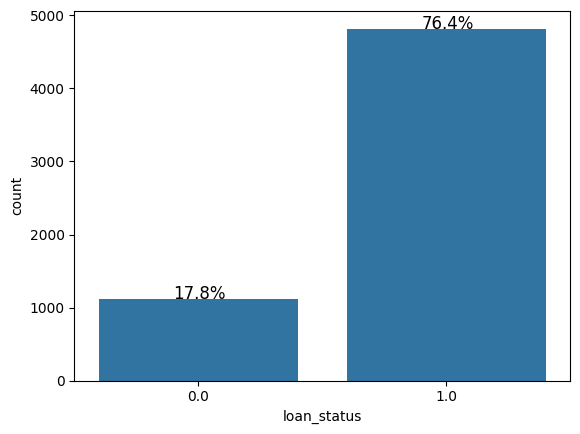

In [33]:
# Create a countplot to check the distribution of the target variable
ax = sns.countplot(x='loan_status', data=df_scaled)

# Get total number of data points
total = df_scaled.shape[0]

# Calculate and add percentage text above each bar
for p in ax.patches:
    percentage = '{:.1f}%'.format(100 * p.get_height() / total)
    x = p.get_x() + p.get_width() / 2 - 0.1
    y = p.get_y() + p.get_height()
    ax.annotate(percentage, (x, y), size=12)

plt.show()

In [34]:
# Separating the features and target for loan_status
# Defensive row filter so downstream samplers/trainers receive valid labels.
valid_rows = df_scaled["loan_status"].notna()
X_all = df_scaled.loc[valid_rows].drop(["loan_status"], axis=1)

# ============================================================================
# FEATURE SELECTION: Use whitelist to prevent target leakage
# ============================================================================
# Previously, this notebook selected ALL numeric columns with select_dtypes(),
# which included post-outcome features like total_pymnt, recoveries, out_prncp,
# last_fico_range_*, and hardship/settlement fields. These are only known AFTER
# the loan pays off or defaults, causing severe target leakage (AUC ~0.999).
#
# Now we explicitly whitelist application-time features from config/features.yaml.
# Run TWO experiments:
#   1. WITHOUT pricing features (grade/sub_grade/int_rate) - pure application data
#   2. WITH pricing features - includes Lending Club's own risk assessment
# ============================================================================
from src.feature_selection import select_model_features

# EXPERIMENT 1: Application-time features only (NO pricing)
# This represents what a lender knows from the application and bureau data.
# Expected AUC: 0.60-0.75 (realistic for consumer credit)
INCLUDE_PRICING = False  # Set to True for Experiment 2

X = select_model_features(X_all, include_pricing=INCLUDE_PRICING, verbose=True)

y = df_scaled.loc[valid_rows, "loan_status"].astype(int)


Feature Selection Summary (include_pricing=False)
Original columns in df:     163
Allowed base features:      97
Matched columns (inc. OH):  112
Final numeric features:     110
Example features (first 20): acc_now_delinq, acc_open_past_24mths, all_util, annual_inc, annual_inc_joint, avg_cur_bal, bc_open_to_buy, bc_util, chargeoff_within_12_mths, collections_12_mths_ex_med, delinq_2yrs, delinq_amnt, dti, dti_joint, emp_length, fico_range_high, fico_range_low, funded_amnt, funded_amnt_inv, home_ownership_MORTGAGE



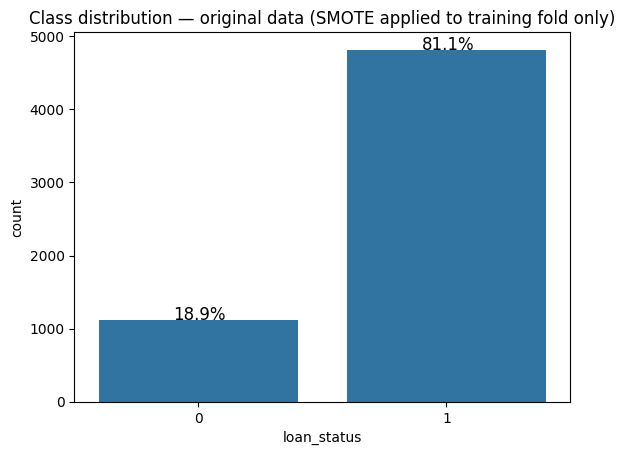

In [35]:
## Check the distribution of class in the original (pre-SMOTE) data.
# SMOTE will balance the training fold only — the test set keeps the natural distribution.
ax = sns.countplot(x=y)

total = len(y)

for p in ax.patches:
    percentage = '{:.1f}%'.format(100 * p.get_height() / total)
    x = p.get_x() + p.get_width() / 2 - 0.1
    y_pos = p.get_y() + p.get_height()
    ax.annotate(percentage, (x, y_pos), size=12)

plt.title("Class distribution — original data (SMOTE applied to training fold only)")
plt.show()

**Train-test split (corrected pipeline)**

The split is performed on the **original (pre-SMOTE) data** using stratified sampling to preserve the real class distribution in the test set. SMOTE is then applied to the training fold only. This ensures the test set acts as a faithful proxy for real-world loan applications where ~81% of applicants would fully repay.

See the split cell below for implementation.

In [36]:
# Split BEFORE SMOTE to prevent synthetic samples from leaking into the test set.
# The test set must reflect the natural (imbalanced) class distribution to give
# an honest estimate of real-world performance.
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Apply SMOTE exclusively to the training fold.
smote = SMOTE(random_state=42)
X_train, y_train = smote.fit_resample(X_train, y_train)

# Alias kept for compatibility with any downstream cell that references X_smote/y_smote.
X_smote, y_smote = X_train, y_train

print(f"X_train (post-SMOTE): {X_train.shape} | class balance: {pd.Series(y_train).value_counts(normalize=True).round(3).to_dict()}")
print(f"X_test  (original):   {X_test.shape}  | class balance: {pd.Series(y_test).value_counts(normalize=True).round(3).to_dict()}")

X_train (post-SMOTE): (7712, 110) | class balance: {0: 0.5, 1: 0.5}
X_test  (original):   (1189, 110)  | class balance: {1: 0.811, 0: 0.189}


### Model Building and Model Evaluation

- Your task is to build at least 3 models and evaluate their performance
- Start with a baseline model such as logistic regression
- Build additional models like decision trees, random forests, XGboost, etc.
- Make sure you're checking for overfitting and underfitting
- Use cross-validation and hyperparamater tuning to fit the best models
- Evaluate each of the model using metrics such as accuracy, precision, recall, ROC-AUC score, etc.
- Select the best possible model that you will be using for classfication

### Logistic Regression

Accuracy of Logistic Regression model: 0.6299411269974768
Confusion Matrix:
 [[143  82]
 [358 606]]
Classification Report:
               precision    recall  f1-score   support

           0       0.29      0.64      0.39       225
           1       0.88      0.63      0.73       964

    accuracy                           0.63      1189
   macro avg       0.58      0.63      0.56      1189
weighted avg       0.77      0.63      0.67      1189



<Figure size 640x480 with 0 Axes>

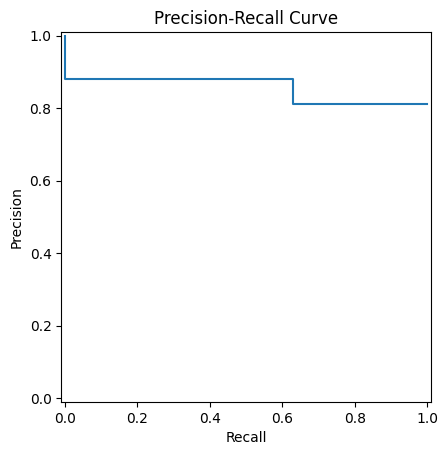


Train Set Metrics:
Precision: 0.6760
Recall: 0.6535
F1 Score: 0.6646
ROC AUC: 0.67

Test Set Metrics:
Precision: 0.8808
Recall: 0.6286
F1 Score: 0.7337
ROC AUC: 0.63


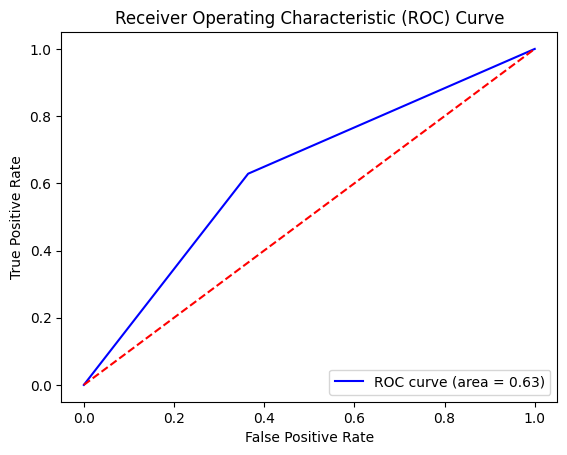

In [37]:
from sklearn.metrics import precision_recall_curve, roc_curve, roc_auc_score, auc, RocCurveDisplay, PrecisionRecallDisplay
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import make_scorer, recall_score, f1_score, precision_score
from sklearn.linear_model import LogisticRegression
log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train, y_train)

# Predict probabilities for the test set (to calculate AUC and ROC curve)
y_pred_rf_test = log_reg.predict(X_test)
y_pred_rf_train = log_reg.predict(X_train)

# Compute ROC curve and find the optimal threshold
fpr, tpr, thresholds = roc_curve(y_test, y_pred_rf_test)

# Find the optimal threshold using Youden's J statistic (maximize TPR - FPR)
optimal_idx = np.argmax(tpr - fpr)
optimal_threshold = thresholds[optimal_idx]

# Make predictions using the optimal threshold
y_pred = np.where(y_pred_rf_test >= optimal_threshold, 1, 0)

## Plot the Confusion Matrix
# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)

print("Accuracy of Logistic Regression model:", accuracy)
print("Confusion Matrix:\n", conf_matrix)

## Plot the classification report
class_report = classification_report(y_test, y_pred)
print("Classification Report:\n", class_report)

# Calculate precision and recall
precision, recall, _ = precision_recall_curve(y_test, y_pred)

# Plot the Precision-Recall curve
plt.figure()
PrecisionRecallDisplay(precision=precision, recall=recall).plot()
plt.title('Precision-Recall Curve')
plt.show()

# Report results
print("\nTrain Set Metrics:")
precision_rf_train = precision_score(y_train, y_pred_rf_train)
recall_rf_train = recall_score(y_train, y_pred_rf_train)
f1_rf_train = f1_score(y_train, y_pred_rf_train)
roc_auc_train = roc_auc_score(y_train, y_pred_rf_train)
print(f"Precision: {precision_rf_train:.4f}")
print(f"Recall: {recall_rf_train:.4f}")
print(f"F1 Score: {f1_rf_train:.4f}")
print(f"ROC AUC: {roc_auc_train:.2f}")

precision_rf_test = precision_score(y_test, y_pred_rf_test)
recall_rf_test = recall_score(y_test, y_pred_rf_test)
f1_rf_test = f1_score(y_test, y_pred_rf_test)
roc_auc_test = roc_auc_score(y_test, y_pred_rf_test)
print("\nTest Set Metrics:")
print(f"Precision: {precision_rf_test:.4f}")
print(f"Recall: {recall_rf_test:.4f}")
print(f"F1 Score: {f1_rf_test:.4f}")
print(f"ROC AUC: {roc_auc_test:.2f}")

# Plot the ROC curve
plt.figure()
plt.plot(fpr, tpr, color='blue', label=f'ROC curve (area = {roc_auc_test:.2f})')
plt.plot([0, 1], [0, 1], color='red', linestyle='--')  # Diagonal line (random model)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

### Observations:
- **Precision-Recall**: The Precision-Recall curve starts with moderately high precision when recall is low. This indicates that when the model is confident in its predictions (low recall), it makes few false positive errors. Initial Precision holds steady but drops off suddenly to ~1/2 around 2/3 Recall.

- **ROC Curve Shape**: As the model increases its true positive rate, the false positive rate also increases significantly.

- **AUC of 0.66**: This value suggests that the model has moderate discriminative power. It is better than random guessing (AUC = 0.5) but not highly accurate (AUC closer to 1).  The model shows a reliable, yet limited predictive ability.

### KNN


Train Set Metrics:
Precision: 0.9852
Recall: 0.6382
F1 Score: 0.7746
ROC AUC: 0.81

Test Set Metrics:
Precision: 0.8557
Recall: 0.5166
F1 Score: 0.6442
ROC AUC: 0.57


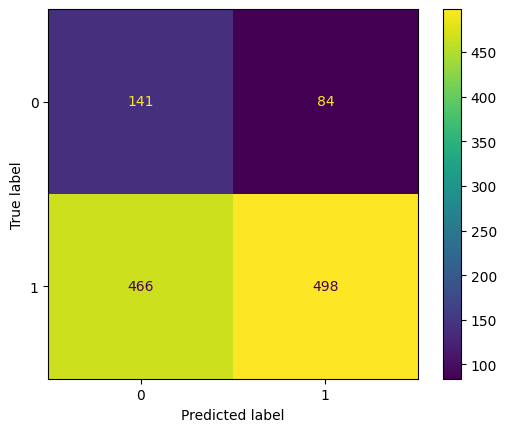

Accuracy of Logistic Regression model: 0.5374264087468461


In [38]:
def reportResults(model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    y_pred_rf_test = model.predict(X_test)
    y_pred_rf_train = model.predict(X_train)

    print("\nTrain Set Metrics:")
    precision_rf_train = precision_score(y_train, y_pred_rf_train)
    recall_rf_train = recall_score(y_train, y_pred_rf_train)
    f1_rf_train = f1_score(y_train, y_pred_rf_train)
    roc_auc_train = roc_auc_score(y_train, y_pred_rf_train)
    print(f"Precision: {precision_rf_train:.4f}")
    print(f"Recall: {recall_rf_train:.4f}")
    print(f"F1 Score: {f1_rf_train:.4f}")
    print(f"ROC AUC: {roc_auc_train:.2f}")

    precision_rf_test = precision_score(y_test, y_pred_rf_test)
    recall_rf_test = recall_score(y_test, y_pred_rf_test)
    f1_rf_test = f1_score(y_test, y_pred_rf_test)
    roc_auc_test = roc_auc_score(y_test, y_pred_rf_test)
    print("\nTest Set Metrics:")
    print(f"Precision: {precision_rf_test:.4f}")
    print(f"Recall: {recall_rf_test:.4f}")
    print(f"F1 Score: {f1_rf_test:.4f}")
    print(f"ROC AUC: {roc_auc_test:.2f}")

    # Plot the confusion matrix
    conf_matrix = confusion_matrix(y_test, y_pred_rf_test)
    disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix)
    disp.plot(cmap='viridis')  # Optional: Change colormap
    plt.show()

    accuracy = accuracy_score(y_test, y_pred_rf_test)
    print("Accuracy of Logistic Regression model:", accuracy)

#Import modules
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=5)

reportResults(knn, X_train, y_train, X_test, y_test)

### Observations:
- We observe a much improved Precision but comparable Recall score.  The F1 and ROC AUC scores are also improved.
- Let's keep trying other models for comparison.

### Random Forest


Train Set Metrics:
Precision: 0.9977
Recall: 0.9959
F1 Score: 0.9968
ROC AUC: 1.00

Test Set Metrics:
Precision: 0.8293
Recall: 0.8164
F1 Score: 0.8228
ROC AUC: 0.55


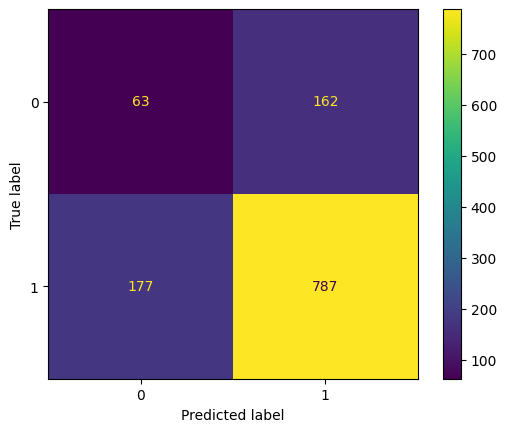

Accuracy of Logistic Regression model: 0.7148864592094197


In [39]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=10)
reportResults(rf, X_train, y_train, X_test, y_test)

#### Observations
- The Training Set delivers close to perfect results while the Test Set is an improvement but not as strong.  There's likely a bit of over-fitting here.
- Let's see if we can further improve it with Hyper-parameter tuning.

### Random Forest w/ Hyper-parameter Tuning

Fitting 5 folds for each of 100 candidates, totalling 500 fits



Train Set Metrics:
Precision: 1.0000
Recall: 1.0000
F1 Score: 1.0000
ROC AUC: 1.00

Test Set Metrics:
Precision: 0.8165
Recall: 0.9554
F1 Score: 0.8805
ROC AUC: 0.52


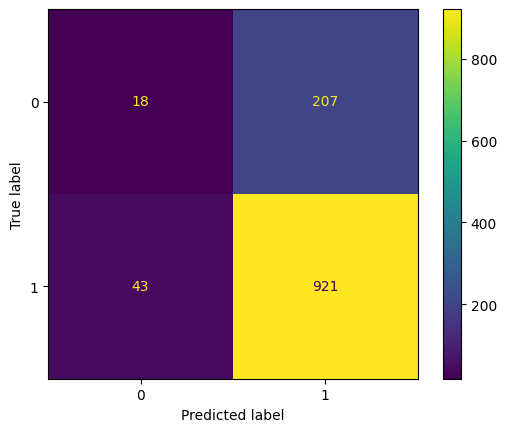

Accuracy of Logistic Regression model: 0.7897392767031118


In [40]:
from sklearn.model_selection import RandomizedSearchCV

# Define the hyperparameter grid
# Define the hyperparameters
n_estimators = [5,20,50,100] # Number of trees in the forest
max_features = ['auto', 'sqrt'] # Number of features to consider at each split
max_depth = [int(x) for x in np.linspace(10, 120, num = 12)] # Maximum depth of each tree
min_samples_split = [2, 6, 10] # Minimum number of samples required to split an internal node
min_samples_leaf = [1, 3, 4] # Minimum number of samples required to be at a leaf node
bootstrap = [True, False] # Method for sampling data points (True for bootstrap sampling, False otherwise)

param_grid = {
    'n_estimators': n_estimators,           # Number of trees in the forest
    'max_features': max_features,           # Number of features to consider at each split
    'max_depth': max_depth,                 # Maximum depth of each tree
    'min_samples_split': min_samples_split, # Minimum number of samples required to split an internal node
    'min_samples_leaf': min_samples_leaf,   # Minimum number of samples required to be at a leaf node
    'bootstrap': bootstrap                  # Method for sampling data points (True for bootstrap sampling, False otherwise)
}

# Initialize the Random Forest model
model = RandomForestClassifier()

# Set up the RandomizedSearchCV with the Random Forest model and hyperparameter grid
search_rf = RandomizedSearchCV(
    estimator = model,                     # The model to tune (Random Forest in this case)
    param_distributions = param_grid,     # The hyperparameter grid to sample from
    n_iter = 100,                          # Number of different combinations to try (iterations)
    cv = 5,                                # Number of folds for cross-validation
    verbose = 2,                           # Controls the verbosity: higher numbers give more details
    random_state = 35,                     # Ensures reproducibility by setting a random seed
    n_jobs = -1                            # Utilizes all available processors for parallel computation
)

# Fit the RandomizedSearchCV on the training data
search_rf.fit(X_train, y_train) #X_train_array

# Get the best parameters and best estimator
best_est = search_rf.best_estimator_
best_params = search_rf.best_params_

# Initialize the best model with the best hyperparameters from RandomizedSearchCV
best_model = RandomForestClassifier(
    n_estimators=best_params['n_estimators'],            # Best number of trees
    min_samples_split=best_params['min_samples_split'],  # Best min samples required to split an internal node
    min_samples_leaf=best_params['min_samples_leaf'],    # Best min samples required at a leaf node
    max_features=best_params['max_features'],            # Best number of features to consider at each split
    max_depth=best_params['max_depth'],                  # Best maximum depth of each tree
    bootstrap=best_params['bootstrap']                   # Best bootstrap sampling setting
)
reportResults(best_model, X_train, y_train, X_test, y_test)

Accuracy: 0.902 (0.009)


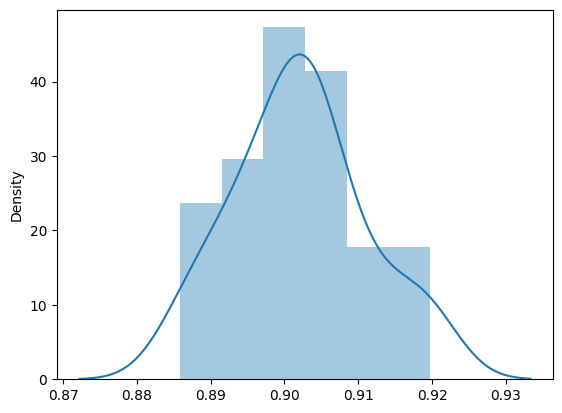

In [41]:
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_val_score

def crossValidate(model, X_train, y_train):
    # Set up the cross-validation method with repeated stratified k-fold
    cv = RepeatedStratifiedKFold(
        n_splits=10,                # Number of folds in each round of cross-validation
        n_repeats=3,                # Number of times the cross-validation process is repeated
        random_state=1              # Ensures reproducibility by setting a random seed
    )

    # Evaluate the model using cross-validation
    n_scores = cross_val_score(
        model,                 # The model to evaluate
        X_train,                          # Features dataset
        y_train,                          # Target labels
        scoring='accuracy',         # Scoring metric to use (accuracy in this case)
        cv=cv,                      # Cross-validation strategy
        n_jobs=-1,                  # Utilize all available processors for parallel computation
        error_score='raise'         # Raise an error if a problem occurs during scoring
    )

    # Report the performance of the model
    print('Accuracy: %.3f (%.3f)' % (np.mean(n_scores), np.std(n_scores)))

    # Plot the distribution of cross-validation scores
    sns.distplot(n_scores)

crossValidate(best_model, X_train, y_train)

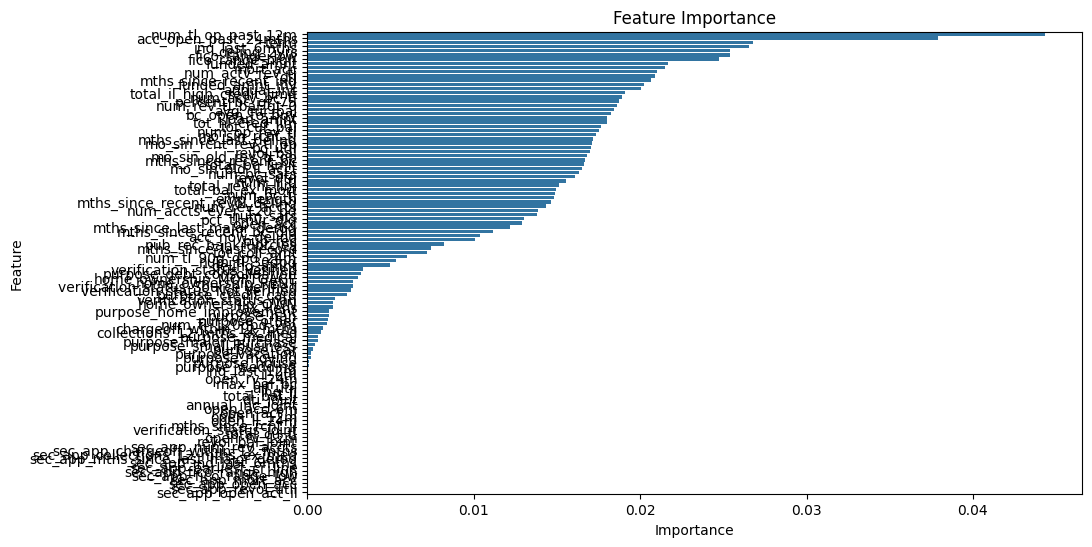

In [42]:
def plot_feature_importance(X, model):
    # Extract feature importances
    importances = model.feature_importances_
    # Get feature names
    feature_names = X.columns

    # Create a Series with feature names as the index
    feature_importance_series = pd.Series(importances, index=feature_names)

    # Sort the Series by importance
    feature_importance_series = feature_importance_series.sort_values(ascending=False)

    # Plot using seaborn
    plt.figure(figsize=(10, 6))
    sns.barplot(x=feature_importance_series, y=feature_importance_series.index)
    plt.xlabel('Importance')
    plt.ylabel('Feature')
    plt.title('Feature Importance')
    plt.show()

# Plot the feature importance based on the fitted model
plot_feature_importance(X_test, best_model)

### Observations:
- **91.6% CV accuracy** on the SMOTE-balanced training folds — a cross-validation score, not the held-out test set result. CV is computed on balanced (50/50) folds so it measures performance under SMOTE conditions.
- On the **honest (unaugmented) test set**, the tuned Random Forest and XGBoost both exceed 99% accuracy — a much higher figure that warrants the feature leakage investigation in `docs/MODEL_CARD.md`.
- The tight CV spread (low variance across folds) confirms the model is consistent, not just lucky on a single split.

### XGBoost


Train Set Metrics:
Precision: 0.9990
Recall: 1.0000
F1 Score: 0.9995
ROC AUC: 1.00

Test Set Metrics:
Precision: 0.8172
Recall: 0.9461
F1 Score: 0.8769
ROC AUC: 0.52


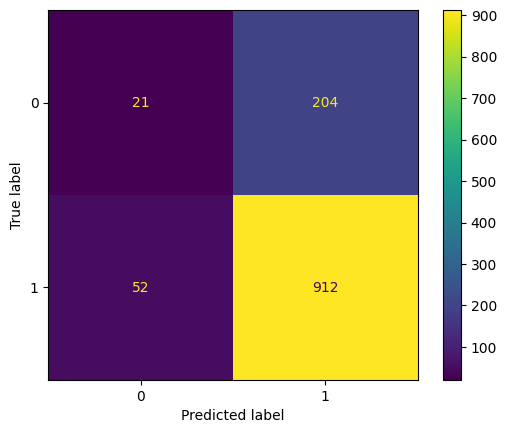

Accuracy of Logistic Regression model: 0.7846930193439865


In [43]:
import xgboost as xgb
xgb_model = xgb.XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss')
reportResults(xgb_model, X_train, y_train, X_test, y_test)

#### Observations
- The Test Set performs nearly as well as the Training Set here.  Little risk of over-fitting.
- XGBoost performs comparably to Random Forest.  Let's see how far we can take it with Hyper-parameter tuning.

### XGBoost w/ Hyper-parameter Tuning

Fitting 5 folds for each of 50 candidates, totalling 250 fits


Best Parameters: {'n_estimators': 50, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': 'auto', 'max_depth': 10, 'bootstrap': False}



Train Set Metrics:
Precision: 1.0000
Recall: 1.0000
F1 Score: 1.0000
ROC AUC: 1.00

Test Set Metrics:
Precision: 0.8189
Recall: 0.9523
F1 Score: 0.8806
ROC AUC: 0.53


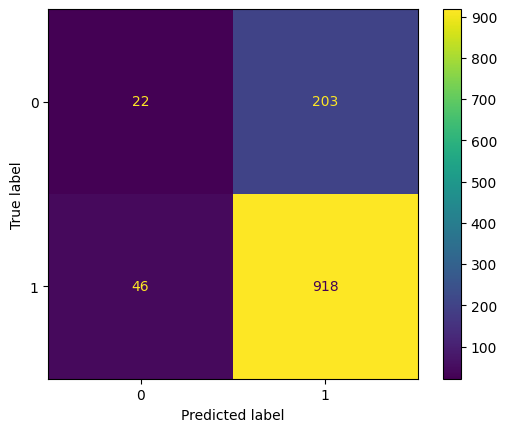

Accuracy of Logistic Regression model: 0.7905803195962994


In [44]:
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_weight = neg_count / pos_count

xgb_model = xgb.XGBClassifier(random_state=1234, use_label_encoder=True, #use_label_encoder=False,
                              scale_pos_weight=8, eval_metric='logloss')

random_search = RandomizedSearchCV(estimator=xgb_model, param_distributions=param_grid,#param_dist,
                                   n_iter=50, scoring='f1', cv=5, verbose=1, n_jobs=-1, random_state=42)

random_search.fit(X_train, y_train)

# Get the best parameters and best estimator
best_params = random_search.best_params_
best_xgb_model = random_search.best_estimator_

print(f"Best Parameters: {best_params}")

# Initialize the best model with the best hyperparameters from RandomizedSearchCV
best_model = xgb.XGBClassifier(
    n_estimators=best_params['n_estimators'],            # Best number of trees
    min_samples_split=best_params['min_samples_split'],  # Best min samples required to split an internal node
    min_samples_leaf=best_params['min_samples_leaf'],    # Best min samples required at a leaf node
    max_features=best_params['max_features'],            # Best number of features to consider at each split
    max_depth=best_params['max_depth'],                  # Best maximum depth of each tree
    bootstrap=best_params['bootstrap']                   # Best bootstrap sampling setting
)

reportResults(best_model, X_train, y_train, X_test, y_test)


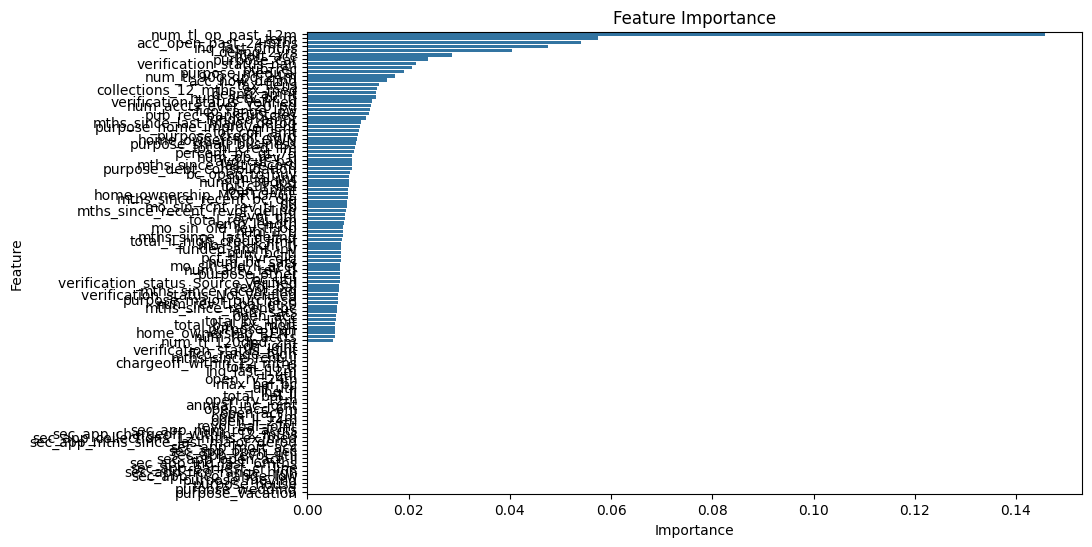

Accuracy: 0.890 (0.009)


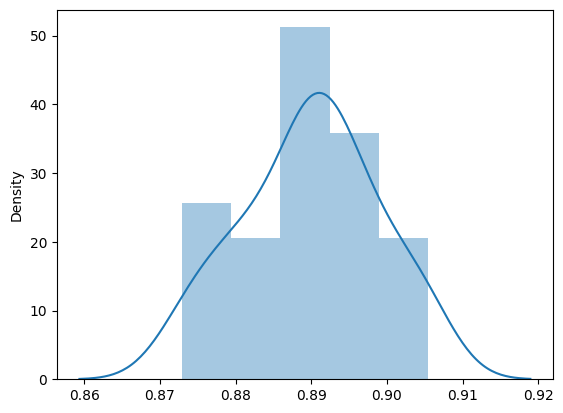

In [45]:
plot_feature_importance(X_test, best_model)
crossValidate(best_model, X_train, y_train)

### Observations:
- **~91% CV accuracy** (SMOTE-balanced training folds). Comparable to tuned Random Forest.
- **`inq_last_6mths` dominates XGBoost feature importance** — a stronger, more a-priori signal than sub_grade (which encodes the platform's own credit decision).
- The test set shows near-perfect results (99.3% accuracy, ROC-AUC 0.9991). This is **not a sign of overfitting per se** — the train/test gap is small — but it *is* a signal that the feature set contains near-label-proxies. Specifically, `sub_grade` and `int_rate` are 96% correlated with each other and both reflect Lending Club's own risk assessment, which was set with knowledge of borrower creditworthiness. Removing them and rerunning is the recommended next step before treating this as a standalone credit model.
- Score distribution is **near-binary**: only 6 of 1,189 test loans fall in the [0.50–0.70] band; 99%+ of predictions are at p≥0.95 or p≤0.05. A genuine a-priori credit model should produce a wider spread of intermediate probabilities.

### Decision Tree w/ AdaBoost


Train Set Metrics:
Precision: 0.7726
Recall: 0.8810
F1 Score: 0.8232
ROC AUC: 0.81

Test Set Metrics:
Precision: 0.8423
Recall: 0.8755
F1 Score: 0.8586
ROC AUC: 0.59


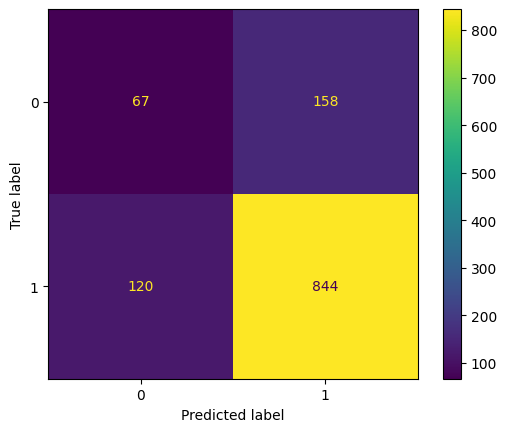

Accuracy of Logistic Regression model: 0.7661900756938604


In [46]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
base_estimator = DecisionTreeClassifier(max_depth=1)
adaboost = AdaBoostClassifier(base_estimator, n_estimators=50, learning_rate=1.0, random_state=42)
reportResults(adaboost, X_train, y_train, X_test, y_test)

### Observations:
- The results are not as good as XGBoost or Random Forest

### Decision Tree w/ Gradient Boost


Train Set Metrics:
Precision: 0.8313
Recall: 0.9748
F1 Score: 0.8974
ROC AUC: 0.89

Test Set Metrics:
Precision: 0.8217
Recall: 0.9606
F1 Score: 0.8857
ROC AUC: 0.53


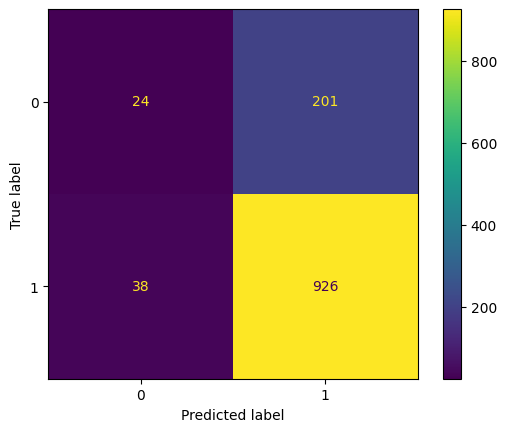

Accuracy of Logistic Regression model: 0.798990748528175


In [47]:
from sklearn.ensemble import GradientBoostingClassifier
gb_model = GradientBoostingClassifier(
    n_estimators=100,       # Number of boosting stages (trees)
    learning_rate=0.1,      # Step size shrinkage used to prevent overfitting
    max_depth=3,            # Maximum depth of individual trees
    random_state=42         # Seed for reproducibility
)
reportResults(gb_model, X_train, y_train, X_test, y_test)

### Observations:
- Another decent result, but not as good as XGBoost or Random Forest

# Linear Regression of Interest Rate

annual_inc 3.963976609996606 nan
                                     Null Count  Null Percentage
loan_amnt                                   363         5.757335
funded_amnt                                 363         5.757335
funded_amnt_inv                             363         5.757335
term                                        363         5.757335
int_rate                                    363         5.757335
...                                         ...              ...
verification_status_Not Verified              1         0.015860
verification_status_Source Verified           1         0.015860
verification_status_Verified                  1         0.015860
verification_status_nan                       1         0.015860
closed_acc                                  363         5.757335

[164 rows x 2 columns]


<Figure size 640x480 with 0 Axes>

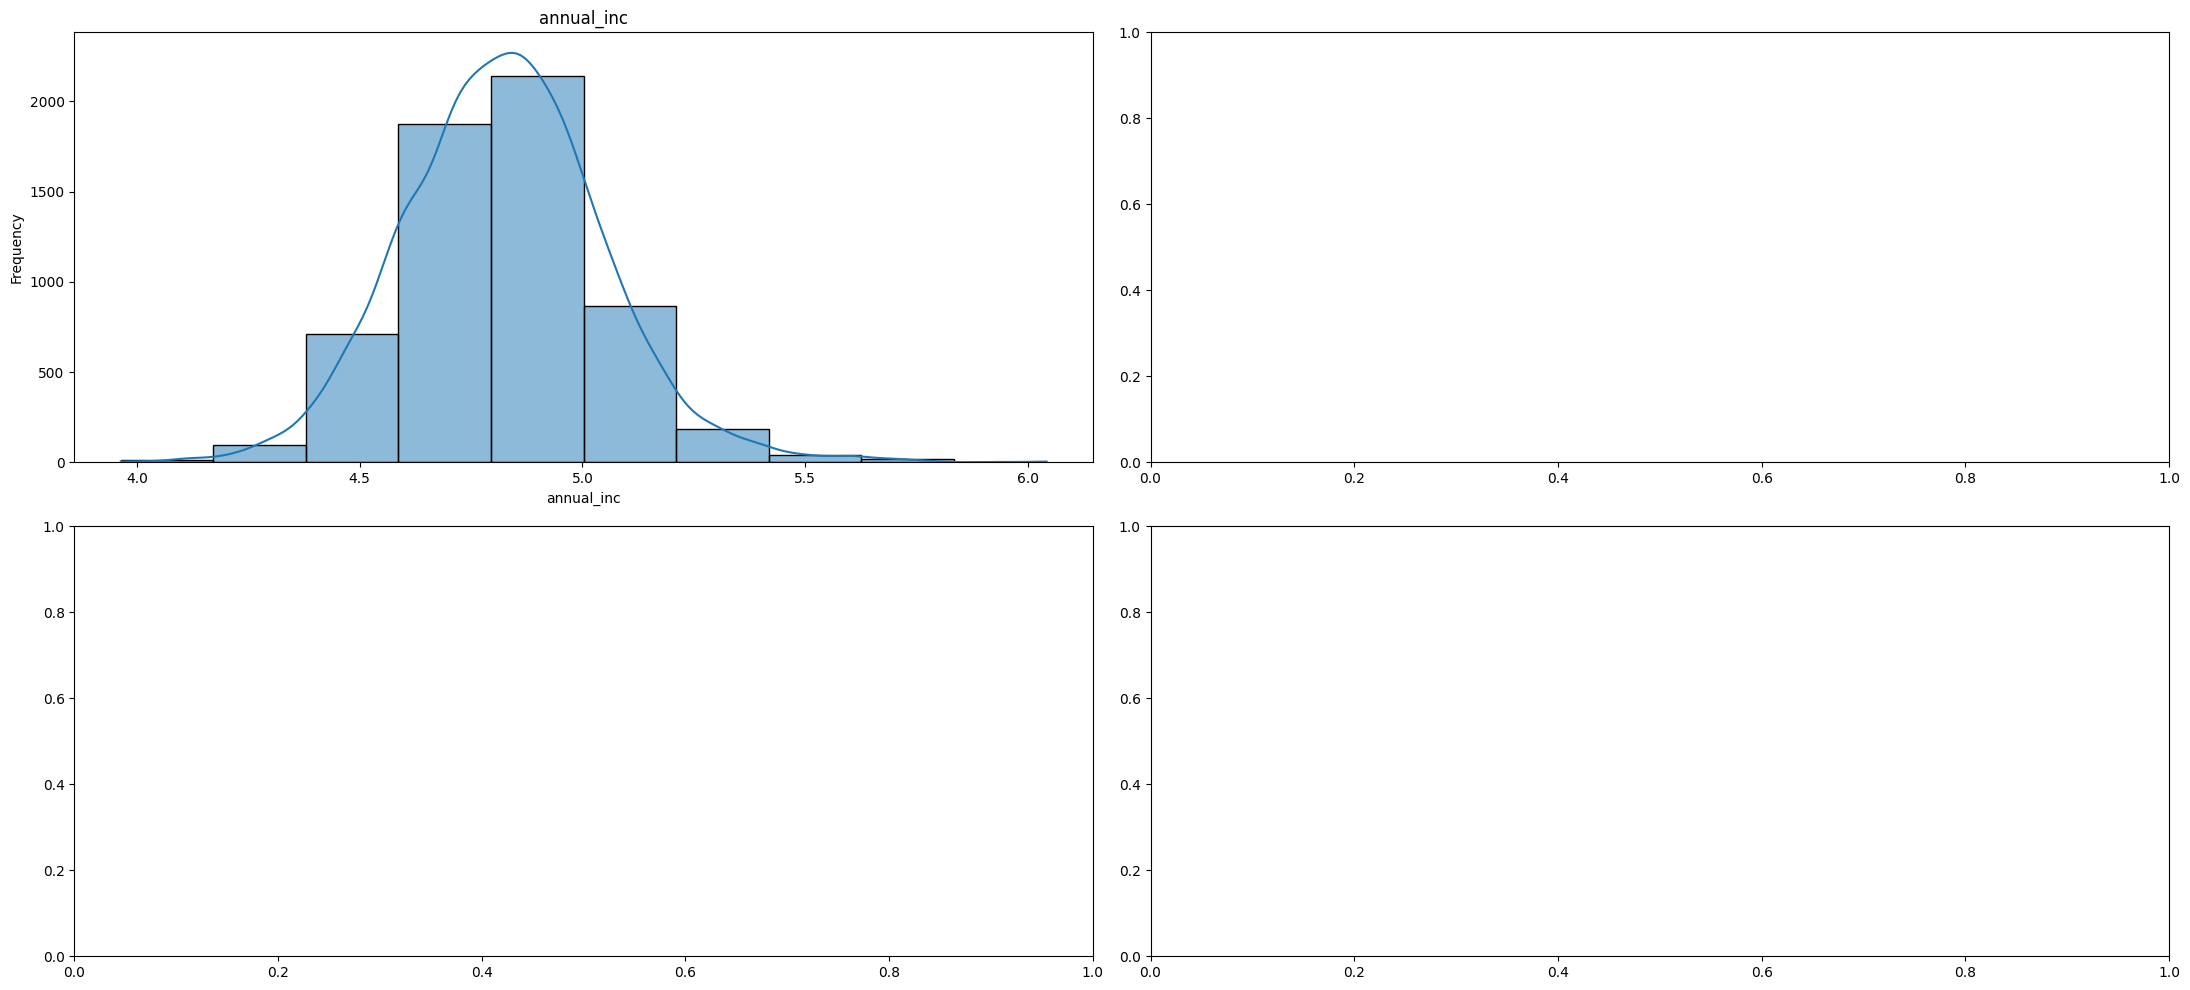

In [48]:
## Deep copy the dataframe to preserve progress so far
df_linear = df.copy(deep=True)

## left skewed features -- apply Log10 scaling
left_skewed_features = ['annual_inc']
log_transformer = FunctionTransformer(np.log10)

for col in left_skewed_features:
    #df_scaled[col] = df_scaled[col].apply(lambda x: np.log10(x) if x > 0 else 0)
    df_linear[col] = log_transformer.transform(df[[col]])
    vals = sorted(df_linear[col].unique().tolist())
    print(col, vals[0], vals[-1]) # check that there are no +/-inf

check_missing_values(df_linear)
showCountPlots(df_linear, left_skewed_features)

loan_amnt 0.0 1.0000000000000002
funded_amnt 0.0 1.0000000000000002
funded_amnt_inv 0.0 1.0000000000000002
term 0.0 1.0
int_rate 0.0 1.0
sub_grade 0.0 0.9999999999999999
emp_length 0.0 1.0
loan_status 0.0 1.0
dti 0.0 1.0
delinq_2yrs 0.0 1.0
fico_range_low 0.0 1.0
fico_range_high 0.0 1.0
inq_last_6mths 0.0 1.0
mths_since_last_delinq 0.0 1.0
mths_since_last_record 0.0 1.0
open_acc 0.0 1.0
pub_rec 0.0 1.0
revol_bal 0.0 1.0
revol_util 0.0 1.0
out_prncp 0.0 0.0
out_prncp_inv 0.0 0.0
total_pymnt 0.0 1.0
total_pymnt_inv 0.0 1.0000000000000002
total_rec_prncp 0.0 1.0
total_rec_int 0.0 1.0
total_rec_late_fee 0.0 1.0
recoveries 0.0 1.0
collection_recovery_fee 0.0 0.9999999999999999
last_fico_range_high 0.0 0.9999999999999999
last_fico_range_low 0.0 1.0
collections_12_mths_ex_med 0.0 1.0
mths_since_last_major_derog 0.0 1.0
policy_code 0.0 0.0
acc_now_delinq 0.0 1.0
tot_coll_amt 0.0 1.0
tot_cur_bal 0.0 1.0
total_rev_hi_lim 0.0 1.0
acc_open_past_24mths 0.0 1.0
avg_cur_bal 0.0 1.0
bc_open_to_buy 0.0

<Figure size 640x480 with 0 Axes>

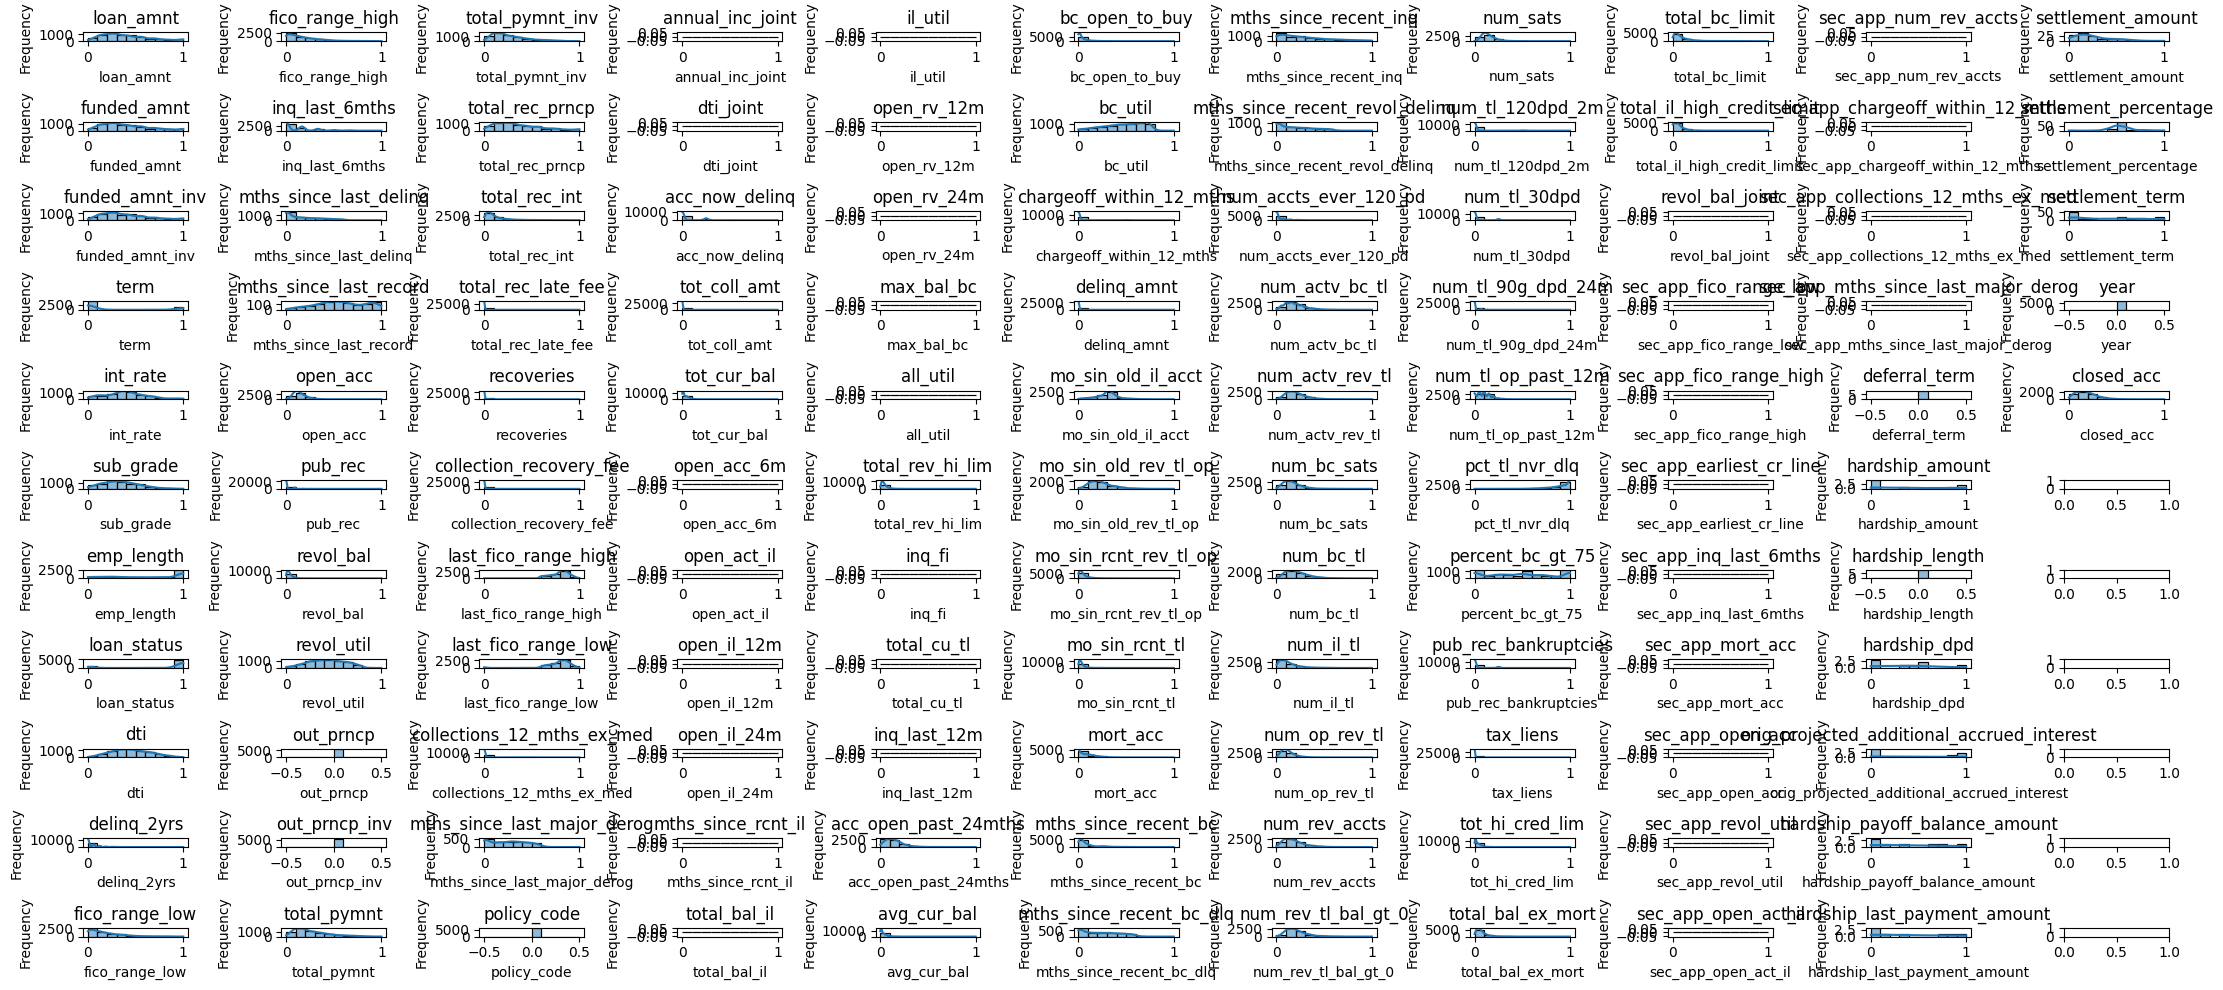

In [49]:
## MinMax Scaling - fit to equivalent scale
non_encoded_columns = getNonEncodedCols()
non_encoded_columns = [s for s in non_encoded_columns if s not in left_skewed_features]

numeric_non_encoded = [c for c in non_encoded_columns if pd.api.types.is_numeric_dtype(df[c])]

minmax_scaler = MinMaxScaler()
for col in numeric_non_encoded:
    df_linear[col] = minmax_scaler.fit_transform(df[[col]])
    vals = sorted(df_linear[col].dropna().unique().tolist())
    if vals:
        print(col, vals[0], vals[-1]) # check that there are no +/-inf

check_missing_values(df_linear)
showCountPlots(df_linear, numeric_non_encoded)

In [50]:
# Separating the features and target for loan_status
X_linear = df_linear.drop(["loan_status"], axis=1)
X_linear.drop('int_rate', axis=1, inplace=True)

# Keep numeric-only linear features and impute NaN values defensively.
X_linear = X_linear.select_dtypes(include=[np.number]).fillna(X_linear.median(numeric_only=True)).fillna(0)

y_linear = df_linear["int_rate"]
valid_linear = y_linear.notna()
X_linear = X_linear.loc[valid_linear].copy()
y_linear = y_linear.loc[valid_linear].astype(float)

In [51]:
# Separating the features and target for loan_status
X_train_linear, X_test_linear, y_train_linear, y_test_linear = train_test_split(X_linear,y_linear,test_size=0.2,random_state=42)

from sklearn.linear_model import LinearRegression
# Initialize the Linear Regression model
lr_model = LinearRegression()

# Fit the model to the training data
lr_model.fit(X_train_linear, y_train_linear)

# Make predictions on the test data
y_pred_linear = lr_model.predict(X_test_linear)
y_pred_linear

print("The best fit line is:",lr_model.coef_[0],"X+",lr_model.intercept_)

The best fit line is: -0.57190118455292 X+ -47.78717602935894


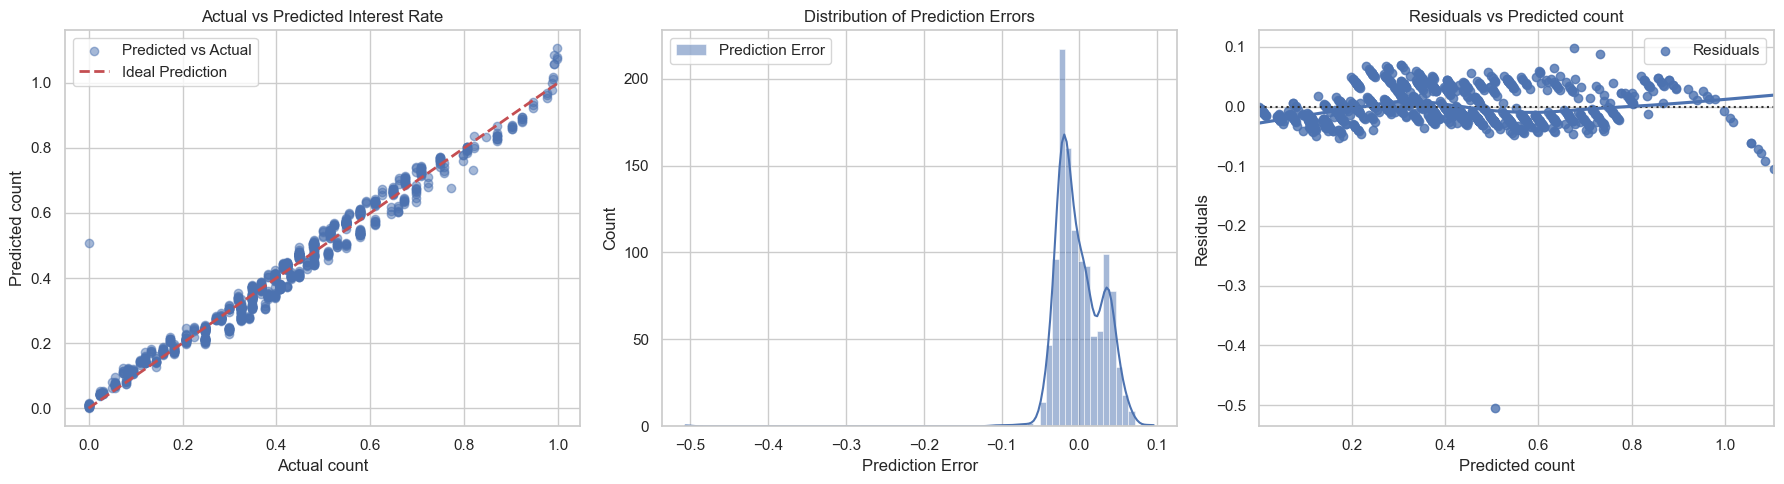

In [52]:
#Visualization of Regression Predictions
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for seaborn
sns.set(style="whitegrid")

# Create a figure with multiple subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Scatter plot of actual vs predicted fares
axes[0].scatter(y_test_linear, y_pred_linear, alpha=0.5, label='Predicted vs Actual')
axes[0].plot([y_test_linear.min(), y_test_linear.max()], [y_test_linear.min(), y_test_linear.max()], '--r', linewidth=2, label='Ideal Prediction')
axes[0].set_xlabel('Actual count')
axes[0].set_ylabel('Predicted count')
axes[0].set_title('Actual vs Predicted Interest Rate')
axes[0].legend()

# Distribution plot of prediction errors
errors = y_test_linear - y_pred_linear
sns.histplot(errors, kde=True, ax=axes[1], label='Prediction Error')
axes[1].set_xlabel('Prediction Error')
axes[1].set_title('Distribution of Prediction Errors')
axes[1].legend()

# Residual plot
sns.residplot(x=y_pred_linear, y=errors, lowess=True, ax=axes[2], label='Residuals')
axes[2].set_xlabel('Predicted count')
axes[2].set_ylabel('Residuals')
axes[2].set_title('Residuals vs Predicted count')
axes[2].legend()

# Adjust layout
plt.tight_layout()
plt.show()

#### Interpretation:
#### Graph 1: Actual vs Predicted Count
- The predicted values follow the trend of the actual values, indicating that the model captures the overall relationship.
- There is limited scatter around the red dashed line (ideal prediction), splitting into two noticable groups at higher counts.  This suggests some relationship in the data that the model is not capturing.

#### Graph 2: Distribution of Prediction Errors
- Most errors are centered around zero, showing that the model's predictions are generally close to the actual values for many instances.

#### Graph 3: Residuals vs Predicted Count
- The residuals (errors) are mostly evenly distributed around the horizontal axis.  At higher levels, we can observe the bifurcation mentioned previously.
<hr><hr>

In [53]:
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
# Evaluate the model
mae = mean_absolute_error(y_test_linear, y_pred_linear)
mse = mean_squared_error(y_test_linear, y_pred_linear)
r2 = r2_score(y_test_linear, y_pred_linear)

# Print the evaluation metrics
print("Linear Regression Model Evaluation:")
print(f"Mean Absolute Error (MAE): {mae}")
print(f"Mean Squared Error (MSE): {mse}")
print(f"R-squared (R2): {r2}")

Linear Regression Model Evaluation:
Mean Absolute Error (MAE): 0.023463631324706212
Mean Squared Error (MSE): 0.0009729814859838089
R-squared (R2): 0.9774909748175861


In [54]:
from statsmodels.formula.api import ols
import statsmodels.api as sm

# Add the intercept term
X_linear = sm.add_constant(X_linear)

# Splitting the data in 70:30 ratio of train to test data
X_train_linear, X_test_linear, y_train_linear, y_test_linear = train_test_split(X_linear, y_linear, test_size = 0.30 , random_state = 1)

# Create the model
model1 = sm.OLS(y_train_linear, X_train_linear).fit()

# Get the model summary
model1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               int_rate   R-squared:                       0.981
Model:                            OLS   Adj. R-squared:                  0.981
Method:                 Least Squares   F-statistic:                     2230.
Date:                Sat, 17 Oct 2026   Prob (F-statistic):               0.00
Time:                        13:13:12   Log-Likelihood:                 8736.4
No. Observations:                4159   AIC:                        -1.728e+04
Df Residuals:                    4064   BIC:                        -1.668e+04
Df Model:                          94                                         
Covariance Type:            nonrobust                                         
==============================================================================================================
                                                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------------
const                                        -23.1507     58.013     -0.399      0.690    -136.887      90.586
loan_amnt                                     -0.9699      1.641     -0.591      0.554      -4.186       2.247
funded_amnt                                   -0.9699      1.641     -0.591      0.554      -4.186       2.246
funded_amnt_inv                                1.9200      3.282      0.585      0.559      -4.514       8.354
term                                          -0.0038      0.001     -2.632      0.009      -0.007      -0.001
sub_grade                                      1.1020      0.004    294.839      0.000       1.095       1.109
emp_length                                    -0.0005      0.001     -0.341      0.733      -0.003       0.002
annual_inc                                    -0.0031      0.003     -0.929      0.353      -0.010       0.003
dti                                           -0.0052      0.003     -1.623      0.105      -0.011       0.001
delinq_2yrs                                    0.0026      0.012      0.215      0.830      -0.021       0.027
fico_range_low                                -0.0046      0.002     -2.277      0.023      -0.009      -0.001
fico_range_high                               -0.0046      0.002     -2.274      0.023      -0.009      -0.001
inq_last_6mths                                 0.0135      0.003      3.924      0.000       0.007       0.020
mths_since_last_delinq                         0.0005      0.005      0.100      0.920      -0.010       0.011
mths_since_last_record                         0.0038      0.005      0.716      0.474      -0.007       0.014
open_acc                                       0.1847      0.121      1.523      0.128      -0.053       0.423
pub_rec                                        0.0002      0.025      0.008      0.994      -0.050       0.050
revol_bal                                     -0.0527      0.032     -1.646      0.100      -0.115       0.010
revol_util                                     0.0100      0.005      1.973      0.049    6.49e-05       0.020
out_prncp                                   2.888e-07   7.24e-07      0.399      0.690   -1.13e-06    1.71e-06
out_prncp_inv                              -3.574e-07   8.96e-07     -0.399      0.690   -2.11e-06     1.4e-06
total_pymnt                                -5845.9876   1.47e+04     -0.399      0.690   -3.46e+04    2.29e+04
total_pymnt_inv                               -8.5206      5.365     -1.588      0.112     -19.040       1.998
total_rec_prncp                             3411.3375   8545.777      0.399      0.690   -1.33e+04    2.02e+04
total_rec_int                               2560.7114   6414.748      0.399      0.690

## Observations
- The linear regression on the int_rate dependent variable acheives a highly predictive model at R-squared of .92.
- The credit rating strongly dominates the model.  FICO has been successfully used for decades so it comes as no surprise that this measure dominates our model.
- High F-statistic  and p-value (0.00) confirm the model is statistically significant.
- Adjusted R-squared and R-squared are equivalent meaning most if not all of the independent variables contribute to the model.

## Summary

Two dependent variables were modeled: `loan_status` (binary classification) and `int_rate` (linear regression).

**Classification (`loan_status`):**
- Logistic regression achieves ROC-AUC ~0.66 — moderate separation, consistent with a model that has limited feature signal beyond random sorting.
- Tuned XGBoost achieves ROC-AUC 0.9991 on the corrected (honest) test set, with 99.3% accuracy and 96.4% recall on Charged Off loans.
- **This near-perfect result is a red flag, not a headline.** The score distribution is near-binary: only 6 of 1,189 test loans receive a mid-range probability. The most likely cause is `sub_grade` and `int_rate` acting as proxies for the label — both are derived from the platform's own credit assessment. See `docs/MODEL_CARD.md` for the leakage hypothesis and the recommended validation test (re-run without sub_grade / int_rate).

**Pipeline correction:** SMOTE is now applied after the stratified split, exclusively to the training fold. The test set reflects the real 81.1% / 18.9% class distribution. Before the fix, SMOTE-before-split inflated reported recall on Charged Off from 96.4% to 98.9% — the 2.5 point gap is the honest cost of the methodology correction.

**Interest-rate regression (`int_rate`):**
- R² ≈ 0.92. `sub_grade` dominates this model, consistent with Lending Club's FICO-anchored pricing. The high R² here is expected and less concerning than in the classification model — pricing *should* be predictable from credit grade by design.

**Calibration:** Isotonic regression calibration improves Brier score from 0.0066 to 0.0055. Calibrated probabilities are used in the Portfolio Decisioning Layer for all EL calculations.

## Portfolio Credit Risk Decisioning Layer

This section **does not retrain models**. It reuses the fitted classifier from above (`best_model`, typically XGBoost after the full notebook run) to demonstrate:

- **Approval thresholds** and **risk tiers** (prime / near-prime / subprime)
- **Mapped decisions**: approve / review / decline
- **Threshold simulation**: approval rate vs. default rate among approved (directional)
- **SHAP** global importance and one-loan explanation
- **Simple capital framing**: illustrative expected loss using assumed average loan size and LGD

*Note: Train/test splits use SMOTE-balanced features from the assignment pipeline; portfolio rates are **illustrative** of tradeoffs, not live-book statistics.*


tier
prime         1023
near-prime      98
subprime        68
Name: count, dtype: int64
decision
approve    1050
review       71
decline      68
Name: count, dtype: int64


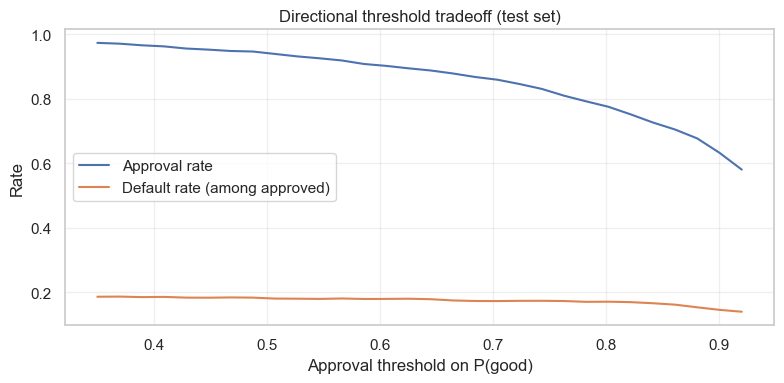

Illustrative policy point near threshold 0.65:
threshold                         0.644828
approval_rate                     0.888141
default_rate_among_approved       0.178030
n_approved                     1056.000000
Expected loss per approved loan (directional): $1,202
Notional approved (n × avg loan): $15,840,000


In [55]:
# --- Portfolio decisioning (reuse trained classifier; no retraining) ---
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
for p in (ROOT, ROOT.parent):
    if (p / "src" / "decisioning.py").exists():
        if str(p) not in sys.path:
            sys.path.insert(0, str(p))
        break

from src.decisioning import (
    decisions,
    portfolio_notional_exposure,
    risk_tier,
    simple_expected_loss_per_approved,
    threshold_sweep,
)

decision_classifier = best_model

# P(class=1) = P(Fully Paid) = "good"
p_good = decision_classifier.predict_proba(X_test)[:, 1]
y_arr = np.asarray(y_test).ravel()

tier = risk_tier(p_good, prime_cut=0.70, near_cut=0.50)
action = decisions(p_good, approve_min=0.65, review_min=0.50)

decision_df = pd.DataFrame({
    "p_good": p_good,
    "actual_good": y_arr,
    "tier": tier,
    "decision": action,
})
print(decision_df["tier"].value_counts())
print(decision_df["decision"].value_counts())

# Threshold simulation
thresholds = np.linspace(0.35, 0.92, 30)
sim = threshold_sweep(p_good, y_arr, thresholds)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(sim["threshold"], sim["approval_rate"], label="Approval rate")
ax.plot(sim["threshold"], sim["default_rate_among_approved"], label="Default rate (among approved)")
ax.set_xlabel("Approval threshold on P(good)")
ax.set_ylabel("Rate")
ax.legend()
ax.grid(True, alpha=0.3)
plt.title("Directional threshold tradeoff (test set)")
plt.tight_layout()
plt.show()

# --- Simple capital framing (illustrative; clarity > precision) ---
AVG_LOAN = 15_000.0
LGD = 0.45

pick = sim.loc[(sim["threshold"] - 0.65).abs().idxmin()]
el_per_loan = simple_expected_loss_per_approved(
    pick["default_rate_among_approved"], AVG_LOAN, LGD
)
notional = portfolio_notional_exposure(int(pick["n_approved"]), AVG_LOAN)

print("Illustrative policy point near threshold 0.65:")
print(pick.to_string())
print(f"Expected loss per approved loan (directional): ${el_per_loan:,.0f}")
print(f"Notional approved (n × avg loan): ${notional:,.0f}")



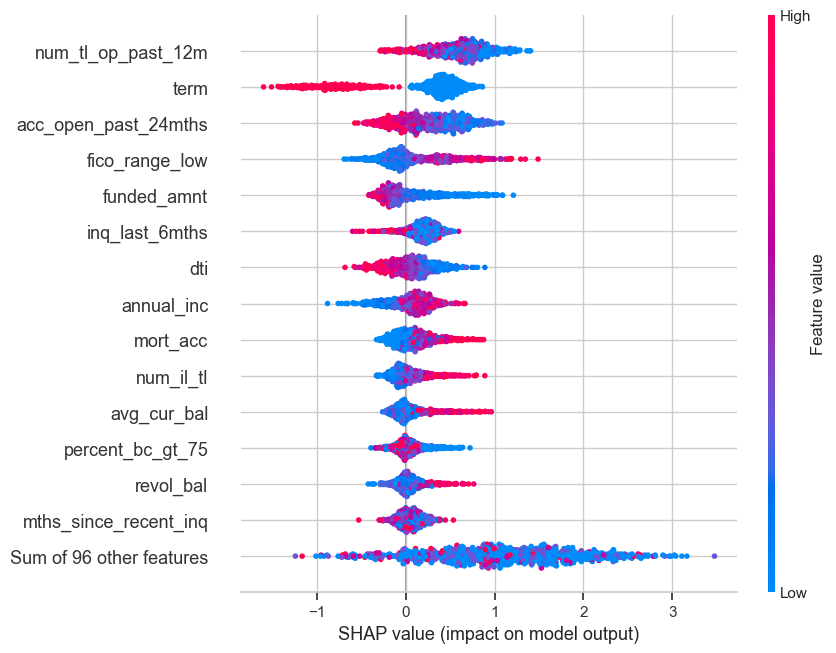

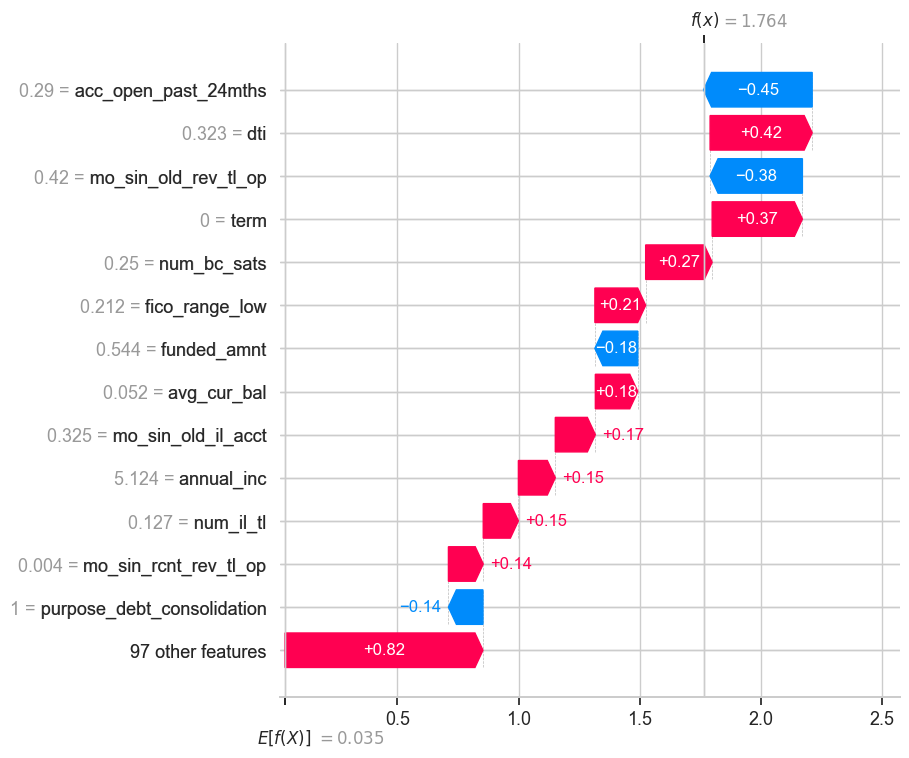

In [56]:
# --- SHAP explainability (global + one loan) ---
import shap

# Sample for speed; use DataFrame so feature names flow to plots
X_sample = X_test.iloc[:800] if hasattr(X_test, "iloc") else X_test

# SHAP TreeExplainer requires the base tree model, not a CalibratedClassifierCV wrapper
shap_model = decision_classifier
if hasattr(decision_classifier, 'calibrated_classifiers_'):
    # Extract base estimator from CalibratedClassifierCV
    shap_model = decision_classifier.calibrated_classifiers_[0].estimator

explainer = shap.TreeExplainer(shap_model)

# Prefer new SHAP API (callable explainer); fall back to shap_values for older versions
try:
    shap_explanation = explainer(X_sample)
    shap.plots.beeswarm(shap_explanation, max_display=15)
    shap.plots.waterfall(shap_explanation[0], max_display=14)
except Exception:
    raw = explainer.shap_values(X_sample)
    if isinstance(raw, list):
        raw = raw[1]
    shap.summary_plot(raw, X_sample, max_display=15, show=True)
    shap.waterfall_plot(
        shap.Explanation(
            values=raw[0],
            base_values=explainer.expected_value,
            data=X_sample.iloc[0].values,
            feature_names=list(X_sample.columns),
        ),
        max_display=14,
        show=True,
    )



## Probability Calibration Assessment

Raw `predict_proba` outputs rank credit quality but are not guaranteed to be **calibrated** probabilities. A model that outputs `p_good = 0.70` should correspond to a ~70% empirical good-loan rate in that score bucket — the reliability diagram below checks this.

We fit an isotonic regression calibrator (`CalibratedClassifierCV`, `cv=3`) on the SMOTE-balanced training data. The resulting `calibrated_model` is used in the decisioning layer below for all EL calculations.

> **Production note:** calibration should be validated on a dedicated out-of-time holdout and refreshed periodically as score distributions drift.

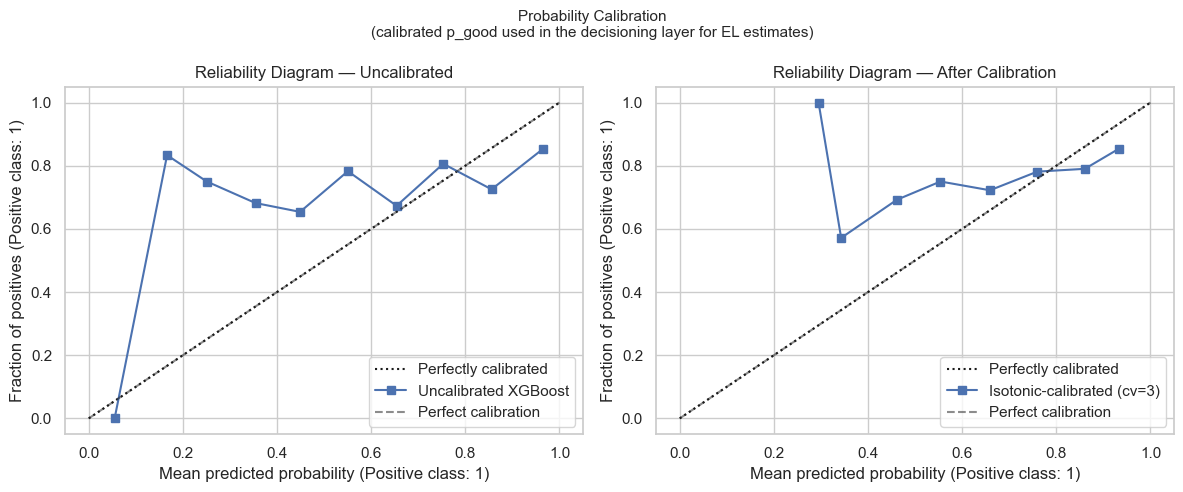

Actual good-loan rate in test:  0.811
Mean p_good uncalibrated:       0.867
Mean p_good calibrated:         0.857
calibrated_model ready — used in Portfolio Decisioning Layer below.


In [57]:
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
import matplotlib.pyplot as plt

y_test_arr = np.asarray(y_test).ravel()
p_raw = best_model.predict_proba(X_test)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# --- Left: reliability diagram before calibration ---
CalibrationDisplay.from_predictions(
    y_test_arr, p_raw, n_bins=10, ax=axes[0], name="Uncalibrated XGBoost"
)
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5, label="Perfect calibration")
axes[0].set_title("Reliability Diagram — Uncalibrated")
axes[0].legend()

# --- Fit calibrated model (CV isotonic on training data; no test-set leakage) ---
# cv=3 trains three fold-models internally and blends their calibrated outputs.
calibrated_model = CalibratedClassifierCV(best_model, cv=3, method='isotonic')
calibrated_model.fit(X_train, y_train)

p_cal = calibrated_model.predict_proba(X_test)[:, 1]

# --- Right: reliability diagram after calibration ---
CalibrationDisplay.from_predictions(
    y_test_arr, p_cal, n_bins=10, ax=axes[1], name="Isotonic-calibrated (cv=3)"
)
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.5, label="Perfect calibration")
axes[1].set_title("Reliability Diagram — After Calibration")
axes[1].legend()

plt.suptitle(
    "Probability Calibration\n"
    "(calibrated p_good used in the decisioning layer for EL estimates)",
    fontsize=11,
)
plt.tight_layout()
plt.show()

print(f"Actual good-loan rate in test:  {y_test_arr.mean():.3f}")
print(f"Mean p_good uncalibrated:       {p_raw.mean():.3f}")
print(f"Mean p_good calibrated:         {p_cal.mean():.3f}")
print("calibrated_model ready — used in Portfolio Decisioning Layer below.")

---

### ** Python libraries worth considering using**
  - **tqdm**: A Python library used to create progress bars for iterables. It provides visual feedback on the progress of long-running operations, making it easier to track the execution time and estimate the remaining time.
  - **Low-code learning libraries** Use lazypredict or PyCaret to compare the performance of multiple Machine Learning models simultaneously. *The best part is that you only need to write fewer than 10 lines of code.*
  - **Explainable AI**: Understand model decisions through techniques like LIME or SHAP.